# **PART I — DATA UNDERSTANDING & EXPLORATORY DATA ANALYSIS**

This part introduces the credit-risk prediction problem, loads the project datasets, examines their structure and roles, and performs exploratory data analysis before any model training or formal feature selection.

# **1. Project Objective and Evaluation Framework**

## **1.1 Prediction Objective**

The objective of this project is to develop a binary classification system for predicting the credit risk of loan applicants.

The model estimates whether an applicant belongs to the:

- **Good-credit class**, or
- **Bad-credit class**

The prediction system will later be evaluated using a fixed Nested Cross-Validation framework before a final model is selected.

## **1.2 Target Definition**

The target variable is:

- `bad_credit = 0` → Good credit
- `bad_credit = 1` → Bad credit

In this project, **Bad credit (`1`) is treated as the positive class**.

Therefore:

- **TP**: Bad applicant correctly predicted as Bad
- **TN**: Good applicant correctly predicted as Good
- **FP**: Good applicant incorrectly predicted as Bad
- **FN**: Bad applicant incorrectly predicted as Good

## **1.3 Business Cost**

The project uses an asymmetric misclassification cost:

\[
Cost = 5FN + FP
\]

where:

- `FN` represents a Bad-credit applicant incorrectly classified as Good,
- `FP` represents a Good-credit applicant incorrectly classified as Bad.

A False Negative is therefore considered five times more costly than a False Positive.

This cost function will later be used for classification-threshold selection and model comparison.

## **1.4 Evaluation Metrics**

Because the business objective is cost-sensitive and the target may be imbalanced, model performance will not be judged by accuracy alone.

The following metrics will be considered:

- Accuracy
- Precision
- Recall
- ROC-AUC
- Average Precision
- Brier Score
- Business Cost

The primary decision criterion is the business cost:

\[
Cost = 5FN + FP
\]

Probability-based metrics such as ROC-AUC, Average Precision, and Brier Score will also be used to evaluate the quality of predicted probabilities.

# **2. Data Loading**

The project uses three predefined datasets:

- Development data
- Historical benchmark data
- Competition data

These datasets have different roles and must remain separated throughout the modelling process.

## **2.1 Import Libraries**

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

## **2.2 Project paths**

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

DATA_PATH = PROJECT_ROOT / "data_splits_colab" / "data_split"

ARTIFACT_DIR = (PROJECT_ROOT / "artifacts")

## **2.3 Load Development, Benchmark, and Competition Data**


In [3]:
development = pd.read_csv(
    DATA_PATH / "development_640.csv"
)

benchmark = pd.read_csv(
    DATA_PATH / "historical_benchmark_160.csv"
)

competition = pd.read_csv(
    DATA_PATH / "competition_200.csv"
)

In [4]:
print("Development:", development.shape)
print("Benchmark:", benchmark.shape)
print("Competition:", competition.shape)

Development: (640, 22)
Benchmark: (160, 22)
Competition: (200, 21)


## **2.4 Rename Columns**

In [5]:
rename_map = {
    "laufkont": "status",
    "laufzeit": "duration",
    "moral": "credit_history",
    "verw": "purpose",
    "hoehe": "amount",
    "sparkont": "savings",
    "beszeit": "employment_duration",
    "rate": "installment_rate",
    "famges": "personal_status_sex",
    "buerge": "other_debtors",
    "wohnzeit": "present_residence",
    "verm": "property",
    "alter": "age",
    "weitkred": "other_installment_plans",
    "wohn": "housing",
    "bishkred": "number_credits",
    "beruf": "job",
    "pers": "people_liable",
    "telef": "telephone",
    "gastarb": "foreign_worker"
}

In [6]:
development = development.rename(columns=rename_map)

benchmark = benchmark.rename(columns=rename_map)

competition = competition.rename(columns=rename_map)

In [7]:
development.columns.tolist()

['Id',
 'status',
 'duration',
 'credit_history',
 'purpose',
 'amount',
 'savings',
 'employment_duration',
 'installment_rate',
 'personal_status_sex',
 'other_debtors',
 'present_residence',
 'property',
 'age',
 'other_installment_plans',
 'housing',
 'number_credits',
 'job',
 'people_liable',
 'telephone',
 'foreign_worker',
 'bad_credit']

# **3. Dataset Structure and Roles**

Before performing EDA or model training, the structure and intended role of each dataset are examined.

Maintaining the separation between these datasets is important for preventing information leakage.

## **3.1 Dataset Dimensions**

In [8]:
dataset_dimensions = pd.DataFrame({
    "Dataset": [
        "Development",
        "Historical Benchmark",
        "Competition"
    ],
    "Rows": [
        development.shape[0],
        benchmark.shape[0],
        competition.shape[0]
    ],
    "Columns": [
        development.shape[1],
        benchmark.shape[1],
        competition.shape[1]
    ]
})

dataset_dimensions

,Dataset,Rows,Columns
0,Development,640,22
1,Historical Benchmark,160,22
2,Competition,200,21


## **3.2 Column Overview**

In [9]:
print("Development columns:")
print(development.columns.tolist())

print("\nBenchmark columns:")
print(benchmark.columns.tolist())

print("\nCompetition columns:")
print(competition.columns.tolist())

Development columns:
['Id', 'status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'bad_credit']

Benchmark columns:
['Id', 'status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'bad_credit']

Competition columns:
['Id', 'status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', '

In [10]:
target_check = pd.DataFrame({
    "Dataset": [
        "Development",
        "Historical Benchmark",
        "Competition"
    ],
    "Contains bad_credit": [
        "bad_credit" in development.columns,
        "bad_credit" in benchmark.columns,
        "bad_credit" in competition.columns
    ]
})

target_check

,Dataset,Contains bad_credit
0,Development,True
1,Historical Benchmark,True
2,Competition,False


In [11]:
display(development.head())

,Id,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,bad_credit
0,0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,0
1,2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,0
2,3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,0
3,5,1,10,4,0,2241,1,2,1,3,1,3,1,48,3,1,2,2,1,1,1,0
4,6,1,8,4,0,3398,1,4,1,3,1,4,1,39,3,2,2,2,2,1,1,0


In [12]:
development.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Id                       640 non-null    int64
 1   status                   640 non-null    int64
 2   duration                 640 non-null    int64
 3   credit_history           640 non-null    int64
 4   purpose                  640 non-null    int64
 5   amount                   640 non-null    int64
 6   savings                  640 non-null    int64
 7   employment_duration      640 non-null    int64
 8   installment_rate         640 non-null    int64
 9   personal_status_sex      640 non-null    int64
 10  other_debtors            640 non-null    int64
 11  present_residence        640 non-null    int64
 12  property                 640 non-null    int64
 13  age                      640 non-null    int64
 14  other_installment_plans  640 non-null    int64
 15  housin

## **3.3 Development / Benchmark / Competition Roles**

The datasets have fixed and distinct roles.

### Development Data

The development dataset is used for:

- Exploratory Data Analysis,
- preprocessing design,
- model selection,
- threshold selection,
- Nested Cross-Validation,
- feature-selection experiments,
- and final model selection.

### Historical Benchmark

The historical benchmark is kept outside the model-selection process.

It is used only after the final modelling rule has been frozen, providing an additional diagnostic evaluation.

Benchmark performance must not be used to return to model tuning or feature selection.

### Competition Data

The competition dataset does not contain the target variable.

It is used only for generating the final predictions after the modelling procedure has been completed.

# **4. Exploratory Data Analysis**

Exploratory Data Analysis is performed to understand the quality, distribution, structure, and potential predictive patterns of the development dataset before model training.

The objectives are to:

- assess data quality,
- examine target-class balance,
- study numerical feature distributions,
- investigate categorical feature patterns,
- and identify variables that may require further investigation.

EDA is used to generate hypotheses rather than make final feature-removal decisions.

No predictor will be removed solely because it appears weak in exploratory plots.

## **4.1 Data Quality Assessment**

The development dataset is first examined for:

- missing values,
- duplicated observations,
- duplicated IDs,
- data types,
- and the number of unique values in each variable.

**Quality Summary**

In [13]:
#EDA chỉ dùng Development data -> Đảm bảo k leak
#mục tiêu chính là hiểu data, không dùng miêu tả này để trực tiếp làm features selection

quality_summary = pd.DataFrame({
    "Data_Type": development.dtypes.astype(str),

    "Missing_Count": development.isna().sum(),

    "Missing_Percentage": (development.isna().mean() * 100).round(2),
    
    "Unique_Values": development.nunique()
})

quality_summary

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Id,int64,0,0.0,640
status,int64,0,0.0,4
duration,int64,0,0.0,30
credit_history,int64,0,0.0,5
purpose,int64,0,0.0,10
amount,int64,0,0.0,616
savings,int64,0,0.0,5
employment_duration,int64,0,0.0,5
installment_rate,int64,0,0.0,4
personal_status_sex,int64,0,0.0,4


### **Data Quality Findings**

The development dataset contains no missing values across all variables.

The `Id` column contains 640 unique values, confirming that it serves as an observation identifier rather than a predictive feature.

Although all predictors are currently stored as integer values, many variables represent coded categorical characteristics rather than continuous numerical quantities. Therefore, data type alone will not be used to determine the preprocessing strategy.

The main continuous numerical predictors are:

- `duration`
- `amount`
- `age`

The remaining predictors will be treated as categorical variables during modelling.

**Duplicates**

In [14]:
#check đúp dữ liệu vì nếu bị lặp thì sẽ ảnh hưởng đến cross validation
print("Duplicated rows:", development.duplicated().sum())
print("Duplicated IDs:", development["Id"].duplicated().sum())

Duplicated rows: 0
Duplicated IDs: 0


**Descriptive Overview**

In [15]:
development.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
Id,640.0,477.593750,278.164249,0.0,236.75,472.5,708.25,999.0
status,640.0,2.631250,1.244063,1.0,2.00,2.0,4.00,4.0
duration,640.0,20.756250,12.414085,4.0,12.00,18.0,24.00,72.0
credit_history,640.0,2.606250,1.119450,0.0,2.00,2.0,4.00,4.0
purpose,640.0,2.806250,2.727583,0.0,1.00,2.0,3.00,10.0
amount,640.0,3247.590625,2874.526174,276.0,1360.75,2283.0,3926.50,18424.0
savings,640.0,2.145313,1.585086,1.0,1.00,1.0,3.00,5.0
employment_duration,640.0,3.378125,1.224741,1.0,3.00,3.0,5.00,5.0
installment_rate,640.0,2.943750,1.138304,1.0,2.00,3.0,4.00,4.0
personal_status_sex,640.0,2.692188,0.699162,1.0,2.00,3.0,3.00,4.0


## **4.2 Target Variable Analysis**

The distribution of the target variable is examined to determine the level of class imbalance in the development dataset.

This is particularly important because the positive class represents Bad-credit applicants and False Negatives have a substantially higher business cost.

**Counts and Percentages**

In [16]:
target_counts = (
    development["bad_credit"]
    .value_counts()
    .sort_index()
)
#good và bad có sự chênh lệch tỉ lệ
target_percentages = (
    development["bad_credit"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

target_summary = pd.DataFrame({
    "Class": [
        "Good Credit",
        "Bad Credit"
    ],
    "Count": [
        target_counts.get(0, 0), 
        target_counts.get(1, 0)
    ],
    "Percentage": [
        target_percentages.get(0, 0),
        target_percentages.get(1, 0)
    ]
})

target_summary

,Class,Count,Percentage
0,Good Credit,480,75.0
1,Bad Credit,160,25.0


### **Target Distribution Findings**

The development dataset contains:

- 480 Good-credit applicants (75%)
- 160 Bad-credit applicants (25%)

The target therefore exhibits a moderate class imbalance, with Good-credit applicants occurring approximately three times as often as Bad-credit applicants.

This imbalance reinforces the need to evaluate models using metrics beyond accuracy.

In particular, Recall for the Bad-credit class and the asymmetric business cost

\[
Cost = 5FN + FP
\]

will be important because failing to identify a Bad-credit applicant is substantially more costly than incorrectly rejecting a Good-credit applicant.

## **4.3 Numerical Feature Analysis**

The three continuous numerical predictors are:

- `duration`
- `amount`
- `age`

These variables are examined using descriptive statistics, distribution plots, and boxplots.

The objectives are to investigate:

- their overall distributions,
- possible skewness,
- potential outliers,
- and differences in scale and variability.

This stage is descriptive and does not use predictor–target relationships for feature selection.

### **4.3.1 Numerical Summary Statistics**

In [17]:
numeric_features = [
    "duration",
    "amount",
    "age"
]

numeric_summary = (development[numeric_features].describe().T)

numeric_summary["skewness"] = (development[numeric_features].skew())

numeric_summary

,count,mean,std,min,25%,50%,75%,max,skewness
duration,640.0,20.756250,12.414085,4.0,12.00,18.0,24.0,72.0,1.171777
amount,640.0,3247.590625,2874.526174,276.0,1360.75,2283.0,3926.5,18424.0,2.083587
age,640.0,35.653125,11.234100,19.0,27.00,33.0,42.0,75.0,0.991234


The three numerical variables show positively skewed distributions, meaning that most observations are concentrated at lower or moderate values while a smaller number of large observations create a longer right tail.

`amount` is the most strongly right-skewed variable, with a skewness of 2.08. Its mean (3247.59) is considerably higher than its median (2283), indicating that several large credit amounts pull the average upward. `duration` is also right-skewed, with a skewness of 1.17, while `age` shows moderate positive skewness at 0.99.

All three variables contain 640 observations, indicating that there are no missing values among these numerical predictors in the Development dataset.

These findings are descriptive only. Skewness and extreme values are investigated during EDA but do not automatically justify removing observations or transforming variables.

### **4.3.2 Numerical Distribution**

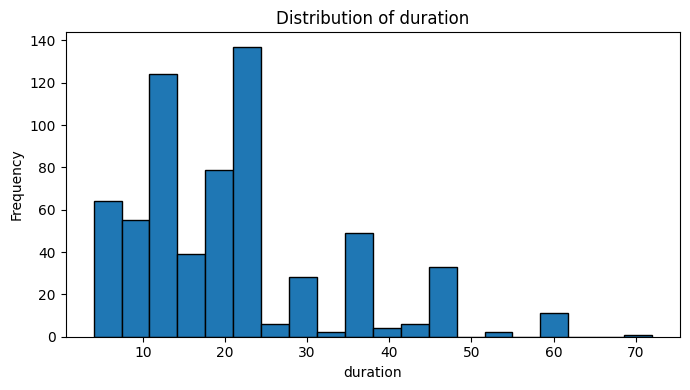

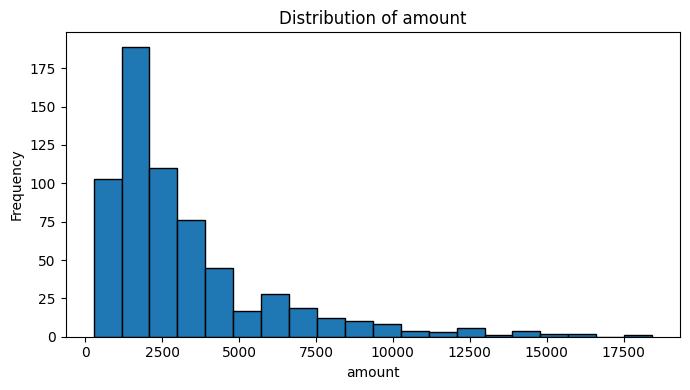

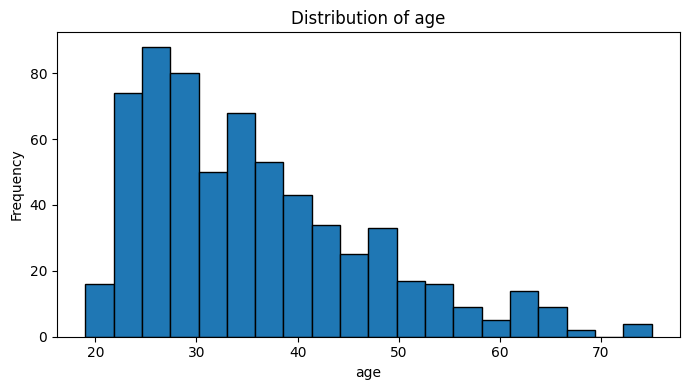

In [18]:
for feature in numeric_features:

    plt.figure(figsize=(7, 4))

    plt.hist(
        development[feature],
        bins=20,
        edgecolor="black"
    )

    plt.title(
        f"Distribution of {feature}"
    )

    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### **4.3.3 Numerical Boxplots**

Boxplots are used to examine the spread of each numerical variable and identify observations located beyond the conventional interquartile-range boundaries.

Potential outliers are investigated but are not automatically removed, because unusually large or small values may represent valid credit applicants rather than data errors.

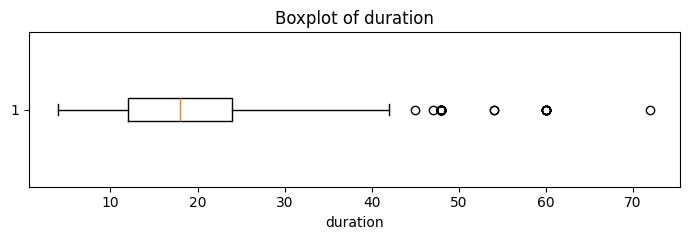

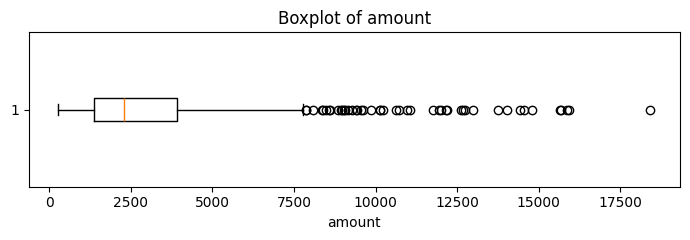

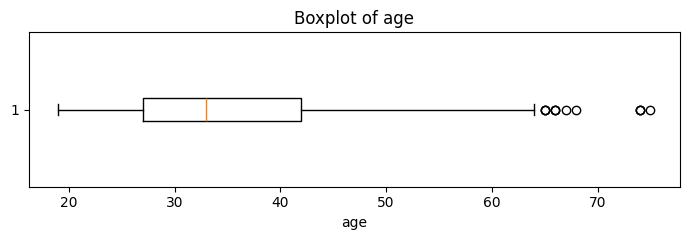

In [19]:
for feature in numeric_features:

    plt.figure(figsize=(7, 2.5))

    plt.boxplot(
        development[feature],
        vert=False
    )

    plt.title(
        f"Boxplot of {feature}"
    )

    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

### **4.3.4 Numerical Correlation**

Pairwise correlations between the continuous numerical predictors are examined to identify strong linear relationships and possible redundancy.

Only the continuous numerical variables are included because integer-coded categorical variables should not be interpreted using ordinary Pearson correlation as if their numerical codes represented continuous quantities.

In [20]:
# Examine pairwise linear relationships between numerical predictors.
# This is target-blind EDA and is used only to identify potential redundancy.
numeric_correlation = (
    development[numeric_features]
    .corr()
)

numeric_correlation

,duration,amount,age
duration,1.000000,0.647294,0.000896
amount,0.647294,1.000000,0.031562
age,0.000896,0.031562,1.000000


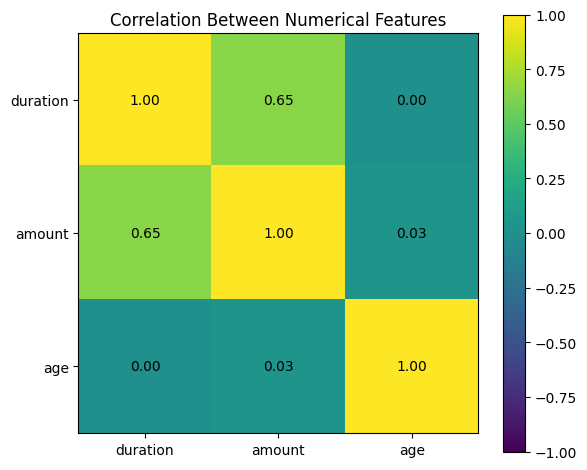

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(
    numeric_correlation,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_features)))

ax.set_yticks(range(len(numeric_features)))

ax.set_xticklabels(numeric_features)

ax.set_yticklabels(numeric_features)

for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        ax.text(
            j,
            i,
            f"{numeric_correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Between Numerical Features")
plt.colorbar(image)
plt.tight_layout()
plt.show()

### **Numerical Feature Findings**

The numerical predictors show different distributional characteristics.

- `duration` is moderately right-skewed, indicating that longer credit durations occur less frequently.
- `amount` is strongly right-skewed and contains several relatively large credit amounts.
- `age` is also right-skewed, with most applicants concentrated in the lower-to-middle age range.

The correlation analysis shows a moderate positive linear relationship between `duration` and `amount`, while `age` has little linear relationship with the other numerical predictors.

Potential outliers are retained because they may represent valid applicants rather than data errors.

No numerical predictor is removed based on the exploratory analysis alone.

## **4.4 Categorical Feature Analysis**

The remaining predictors are categorical variables represented by integer codes.

Although these variables are stored as integers, their values represent categories rather than continuous numerical quantities.

The categorical analysis examines:

- the number of categories,
- category frequencies,
- category imbalance,
- dominant categories,
- and potentially rare categories.

This stage describes the predictor structure without using target relationships for feature selection.

### **4.4.1 Define Categorical Features**

In [22]:
categorical_features = [
    col for col in development.columns
    if col not in (
        ["Id", "bad_credit"]
        + numeric_features
    )
]

print(
    "Number of categorical features:",
    len(categorical_features)
)

categorical_features

Number of categorical features: 17


['status',
 'credit_history',
 'purpose',
 'savings',
 'employment_duration',
 'installment_rate',
 'personal_status_sex',
 'other_debtors',
 'present_residence',
 'property',
 'other_installment_plans',
 'housing',
 'number_credits',
 'job',
 'people_liable',
 'telephone',
 'foreign_worker']

### **4.4.2 Category Frequency Summary**

The frequency structure of each categorical predictor is examined to identify:

- the number of categories,
- the most common category,
- and the degree of concentration in the dominant category.

A highly dominant category may indicate limited variability, but this does not automatically imply that the feature should be removed.

In [23]:
category_summary = []

for feature in categorical_features:

    counts = development[feature].value_counts()

    category_summary.append({
        "Feature": feature,
        "Number_of_Categories": development[feature].nunique(),
        "Most_Common_Category": counts.index[0],
        "Most_Common_Count": counts.iloc[0],
        "Most_Common_Percentage": (
            counts.iloc[0] / len(development) * 100
        )
    })

category_summary = pd.DataFrame(
    category_summary
)

category_summary

,Feature,Number_of_Categories,Most_Common_Category,Most_Common_Count,Most_Common_Percentage
0,status,4,4,261,40.78125
1,credit_history,5,2,315,49.21875
2,purpose,10,3,180,28.12500
3,savings,5,1,372,58.12500
4,employment_duration,5,3,199,31.09375
5,installment_rate,4,4,301,47.03125
6,personal_status_sex,4,3,354,55.31250
7,other_debtors,3,1,578,90.31250
8,present_residence,4,4,258,40.31250
9,property,4,3,215,33.59375


### **4.4.3 Category Distributions**

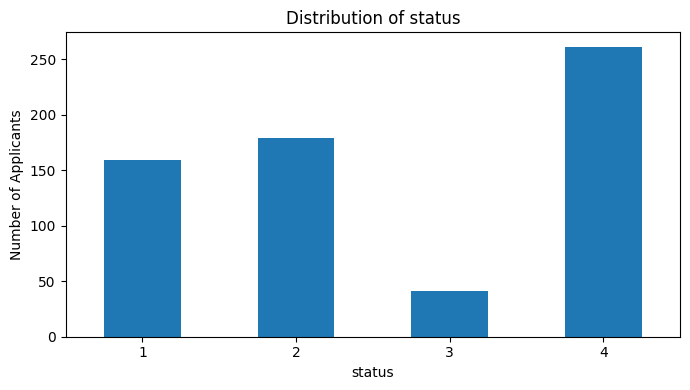

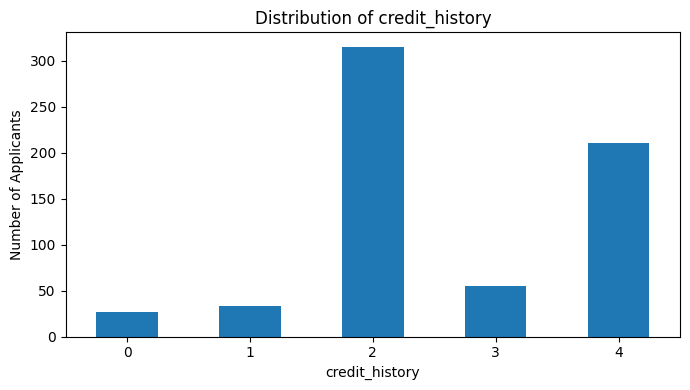

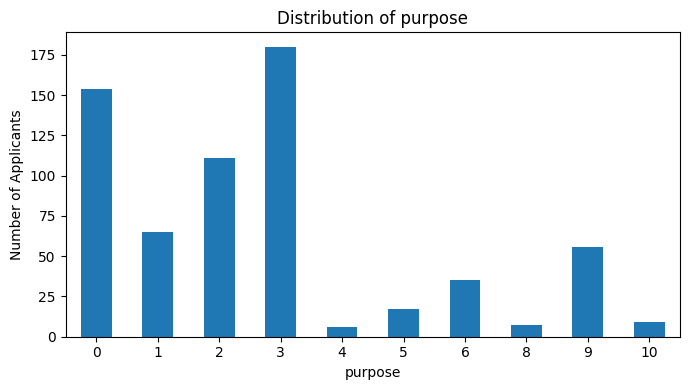

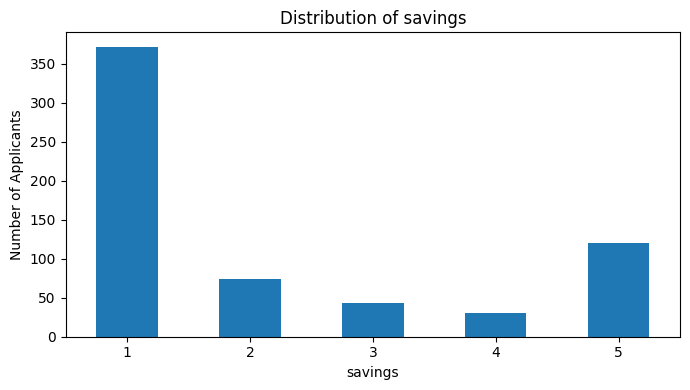

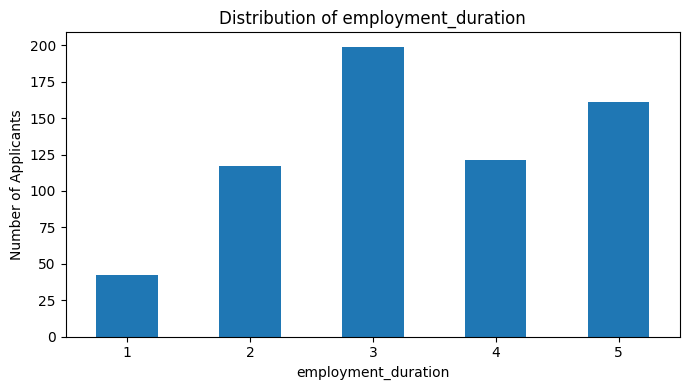

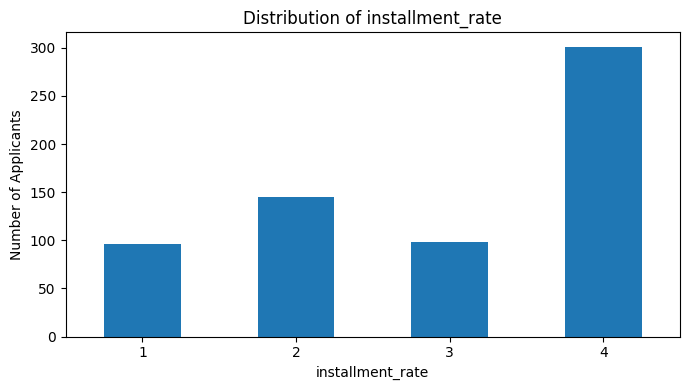

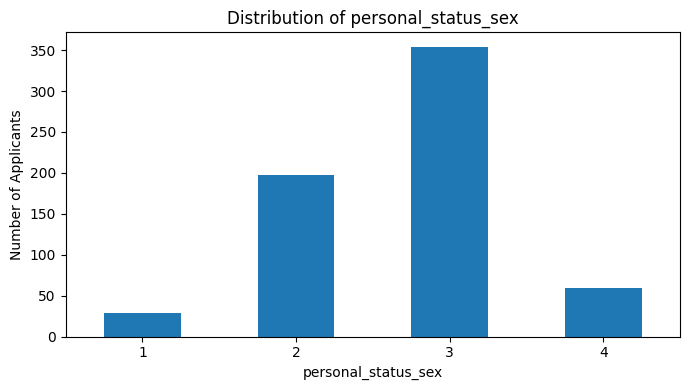

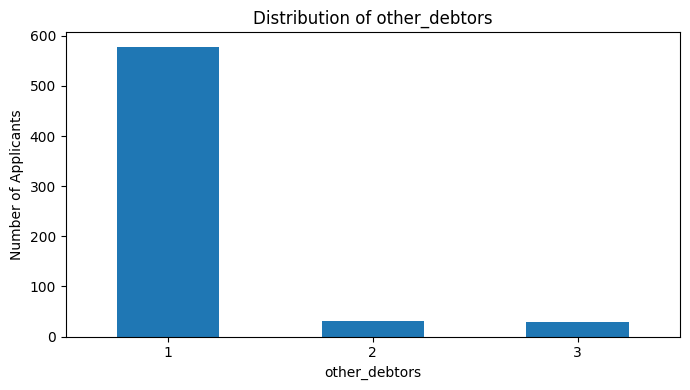

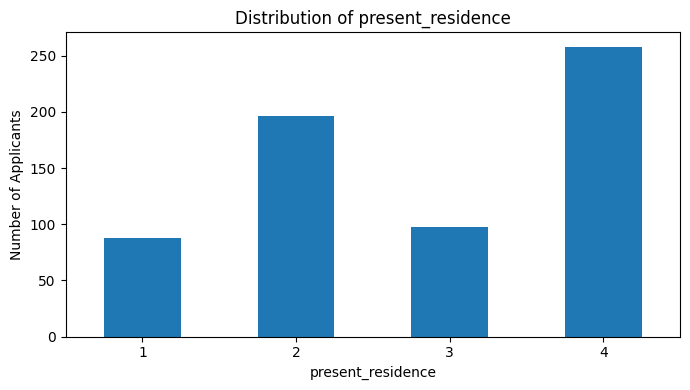

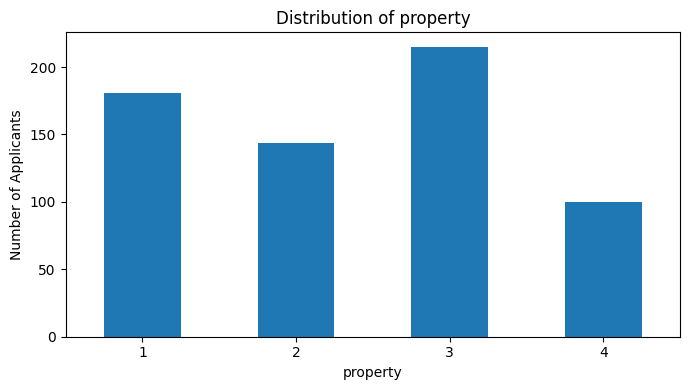

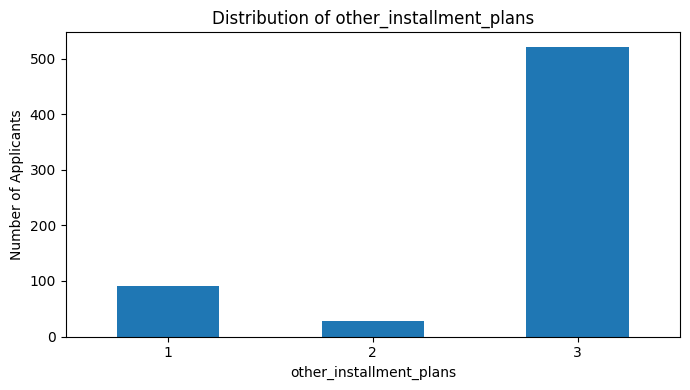

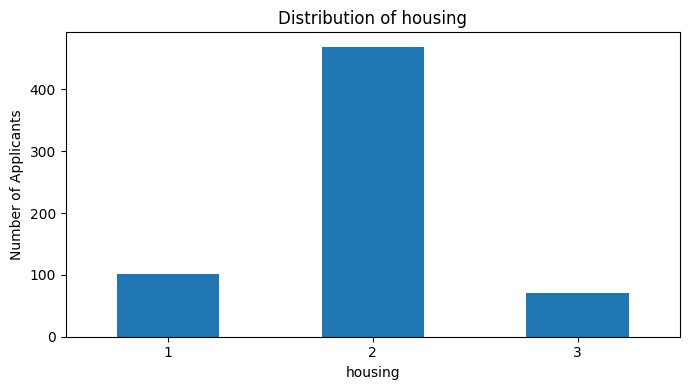

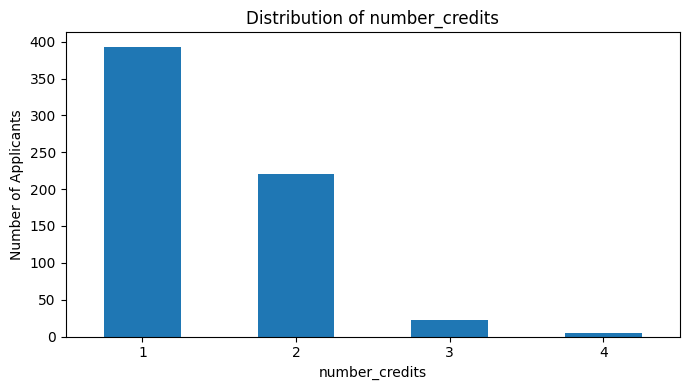

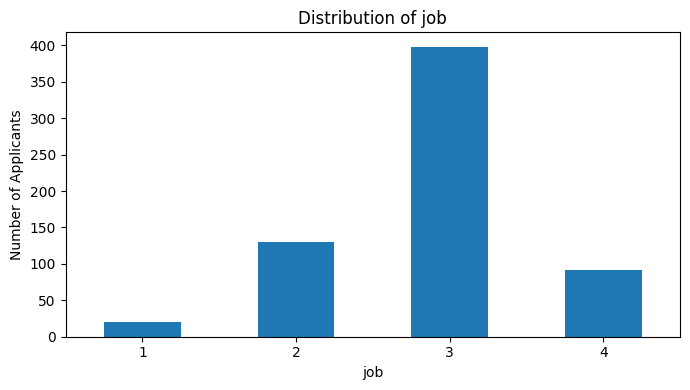

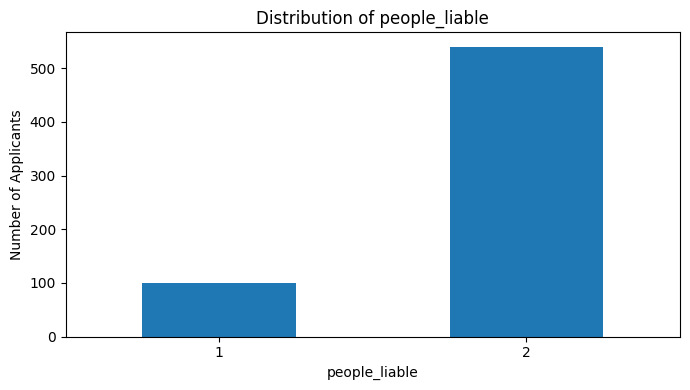

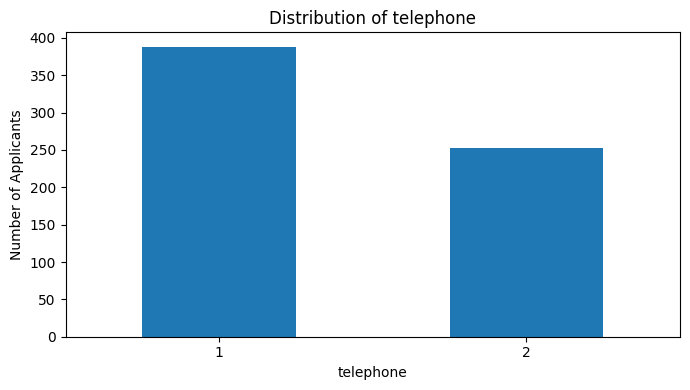

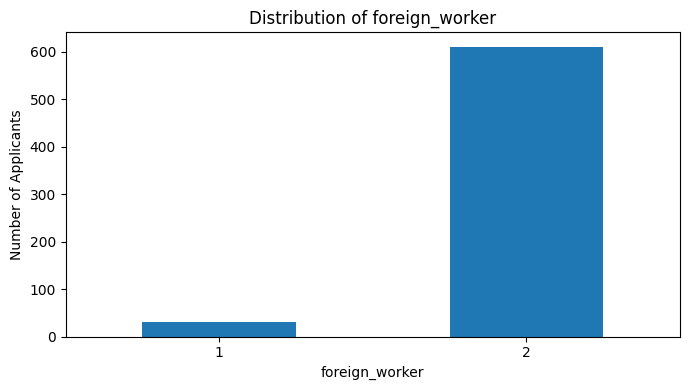

In [24]:
for feature in categorical_features:

    counts = (
        development[feature]
        .value_counts()
        .sort_index()
    )

    plt.figure(figsize=(7, 4))

    counts.plot(kind="bar")

    plt.title(f"Distribution of {feature}")

    plt.xlabel(feature)
    plt.ylabel("Number of Applicants")
    plt.xticks(rotation=0)

    plt.tight_layout()
    plt.show()

### **4.4.4 Rare and Dominant Categories**

In [25]:
# Identify categorical predictors with rare or highly dominant categories.
# These patterns may affect modelling but do not automatically justify feature removal.
rare_dominant_summary = []

for feature in categorical_features:

    proportions = (
        development[feature]
        .value_counts(normalize=True)
    )

    rare_categories = (
        proportions[proportions < 0.05]
        .index
        .tolist()
    )

    dominant_percentage = (proportions.max() * 100)

    rare_dominant_summary.append({
        "Feature": feature,
        "Rare_Categories": rare_categories,
        "Number_of_Rare_Categories": len(rare_categories),
        "Dominant_Category_Percentage": round(
            dominant_percentage, 2
        )
    })

rare_dominant_summary = pd.DataFrame(rare_dominant_summary)

# Show only potentially notable features
rare_dominant_summary[
    (rare_dominant_summary["Number_of_Rare_Categories"] > 0)
    |
    (rare_dominant_summary["Dominant_Category_Percentage"] >= 70)
]

,Feature,Rare_Categories,Number_of_Rare_Categories,Dominant_Category_Percentage
1,credit_history,[0],1,49.22
2,purpose,"[5, 10, 8, 4]",4,28.12
3,savings,[4],1,58.13
6,personal_status_sex,[1],1,55.31
7,other_debtors,[3],1,90.31
10,other_installment_plans,[2],1,81.41
11,housing,[],0,73.28
12,number_credits,"[3, 4]",2,61.41
13,job,[1],1,62.19
14,people_liable,[],0,84.38


### **Rare and Dominant Category Findings**

Several categorical predictors contain rare or highly dominant categories.

Some variables are concentrated heavily in a single category, while others contain categories representing fewer than 5% of observations.

These patterns may indicate limited variability or potentially unstable estimates for rare categories. However, no predictor is removed based on this descriptive analysis alone.

Target-dependent predictor ranking is performed later using the association-based feature-selection procedure within Cross-Validation.

## **4.5 EDA Summary**

The exploratory analysis describes the structure and quality of the Development dataset before modelling.

Key observations include:

- the quality and completeness of the data,
- the class distribution of the target,
- the distributions and skewness of numerical predictors,
- potential numerical outliers,
- and the frequency structure of categorical predictors.

No predictor is removed at this stage.

Target-dependent feature ranking is performed later as part of the Cross-Validation model-selection procedure.

# **PART II — DATA PREPARATION**

This part prepares the development data for modelling.

The predictor and target variables are formally defined, numerical and categorical preprocessing pipelines are constructed, and the fixed cross-validation structure used throughout the project is established.

All preprocessing operations will later be fitted only on training data to prevent information leakage.

# **5. Feature and Target Definition**

The modelling variables are defined using the 640-row development dataset.

The identifier column `Id` is excluded because it uniquely identifies observations and does not represent applicant characteristics.

The target variable `bad_credit` is separated from the predictors.

## **5.1 Define X and y**

In [26]:
X = development.drop(columns=["Id", "bad_credit"]).copy()

y = development["bad_credit"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (640, 20)
y shape: (640,)


In [27]:
print("Number of predictors:",X.shape[1])

print("Target classes:", sorted(y.unique()))

print("\nTarget distribution:")

print(y.value_counts().sort_index())

Number of predictors: 20
Target classes: [np.int64(0), np.int64(1)]

Target distribution:
bad_credit
0    480
1    160
Name: count, dtype: int64


## **5.2 Numerical and Categorical Feature Groups**

The 20 predictors are divided into two preprocessing groups.

### Numerical predictors

- `duration`
- `amount`
- `age`

These variables represent quantitative measurements and will later be median-imputed and standardized.

### Categorical predictors

The remaining 17 predictors are integer-coded categorical variables.

Their numerical codes represent categories rather than continuous quantities and will therefore be processed using categorical preprocessing.

In [28]:
numeric_features = [
    "duration",
    "amount",
    "age"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Numerical features:", len(numeric_features))

print("Categorical features:", len(categorical_features))

print(
    "Total predictors:",
    len(numeric_features)
    + len(categorical_features)
)

Numerical features: 3
Categorical features: 17
Total predictors: 20


In [29]:
print("\nNumerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)


Numerical:
['duration', 'amount', 'age']

Categorical:
['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker']


## **5.3 Final Feature Sanity Check**

Before constructing the preprocessing pipeline, the feature groups are checked to ensure that:

- every predictor belongs to exactly one preprocessing group,
- no predictor is omitted,
- and the identifier and target variables are excluded.

In [30]:
all_defined_features = (
    numeric_features
    + categorical_features
)

print(
    "All X columns included:",
    set(all_defined_features)
    == set(X.columns)
)

print(
    "Duplicate feature assignments:",
    len(all_defined_features)
    - len(set(all_defined_features))
)

print(
    "Id included:",
    "Id" in all_defined_features
)

print(
    "Target included:",
    "bad_credit" in all_defined_features
)

All X columns included: True
Duplicate feature assignments: 0
Id included: False
Target included: False


# **6. Preprocessing Pipeline**

Different preprocessing strategies are required for numerical and categorical predictors.

The preprocessing pipeline is designed so that all data transformations can later be fitted only on training folds during Cross-Validation.

This is important for preventing information leakage.

The preprocessing strategy is:

- numerical predictors → median imputation + standardization,
- categorical predictors → most-frequent imputation + one-hot encoding.

## **6.1 Numerical Pipeline**

The numerical predictors are:

- `duration`
- `amount`
- `age`

Two preprocessing steps are applied.

### Median Imputation

Missing numerical values, if present in future training folds or external datasets, are replaced using the median calculated from the corresponding training data.

Although the current development dataset contains no missing values, the imputation step is retained to make the modelling pipeline robust and consistent.

### Standardization

Numerical variables are standardized using:

\[
z = (x - mean) / std
\]

where:

- \(x\) is the original value,
- \(mean\) is the training-set mean,
- \(std\) is the training-set standard deviation.

Standardization places numerical variables on comparable scales and is particularly important for models such as Logistic Regression, KNN, and SVM.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder)

**Numerical pipeline**

In [32]:
numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipeline

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


## **6.2 Categorical Pipeline**

The remaining 17 predictors are categorical variables represented by integer codes.

Two preprocessing steps are applied.

### Most-Frequent Imputation

Missing categorical values, if present, are replaced using the most frequent category observed in the training data.

### One-Hot Encoding

Each categorical variable is converted into binary indicator columns.

`handle_unknown="ignore"` ensures that a category appearing in validation, benchmark, or competition data but not in the corresponding training data does not cause an error.

In [33]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

categorical_pipeline

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


## **6.3 Combined Preprocessing Transformer**

The numerical and categorical pipelines are combined using a `ColumnTransformer`.

This allows each group of predictors to receive the appropriate preprocessing steps within a single modelling pipeline.

In [34]:
preprocessor = ColumnTransformer([
    ("num",
    numeric_pipeline,
    numeric_features),
    
    ("cat",
    categorical_pipeline,
    categorical_features)
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## **6.4 Leakage Prevention in Preprocessing**

The preprocessing transformer must be fitted only on the training portion of each Cross-Validation fold.

For example, inside one Inner-CV round:

```text
Inner Training
      ↓
fit preprocessing
      ↓
fit model

Inner Validation
      ↓
transform using preprocessing
learned from Inner Training
      ↓
predict

## **6.5 Preprocessing Configuration Check**

In [35]:
print("Numerical pipeline:")
print(numeric_pipeline)

print("\nCategorical pipeline:")
print(categorical_pipeline)

print("\nCombined preprocessor:")
print(preprocessor)

Numerical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Categorical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

Combined preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['duration', 'amount', 'age']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEnc

## **6.6 Preprocessing Summary**

The preprocessing strategy is now fixed for the baseline modelling pipeline.

- `duration`, `amount`, and `age` are median-imputed and standardized.
- The remaining 17 categorical predictors are most-frequent-imputed and one-hot encoded.
- Unknown categorical levels are ignored safely during transformation.
- All preprocessing steps will be fitted only on training folds.
- No preprocessing transformation is fitted globally before Cross-Validation.

This preprocessing design will be used consistently across all candidate models.

# **7. Fixed Cross-Validation Structure**

A fixed Nested Cross-Validation structure is used throughout the project.

The development dataset contains 640 observations.

The evaluation design consists of:

- 5 Outer folds for evaluating the model-selection procedure,
- 3 Inner folds within each Outer Training set for selecting the model configuration and classification threshold.

The same fold assignments will be reused across all candidate models to ensure a fair comparison.

The key principle is:

**Inner CV selects. Outer CV evaluates.**

## **7.1 Cross-Validation Settings**

Stratified splitting is used to preserve the proportion of Good-credit and Bad-credit applicants across folds.

All Cross-Validation settings are fixed before model training and will not be modified according to model performance.

In [ ]:
from sklearn.model_selection import StratifiedKFold

OUTER_FOLDS = 5 #outer fold dùng để đánh giá quy trình chọn mô hình
INNER_FOLDS = 3 #inner fold dùng để chọn model, hyperparameter và threshold

CV_RANDOM_STATE = 42

## **7.2 Create Fixed Outer and Inner Fold Assignments**

In [ ]:
#tạo outer cross validation gồm 5 fold
outer_cv = StratifiedKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True, #xáo trộn dữ liệu trước khi chia
    random_state=CV_RANDOM_STATE
)

fold_records = [] #list

for outer_fold, (outer_train_idx, outer_val_idx) in enumerate( #enumerate đánh số fold, bắt đầu từ fold 1
    outer_cv.split(
        development, #chia dev set thành 5 fold
        development["bad_credit"] #giữ tỉ lệ good/bad dựa trên cột bad_credit
    ),
    start=1
):
#dùng iloc để lấy dữ liệu thật ở các vị trí đó
    # Outer Training
    outer_train_data = (
        development.iloc[outer_train_idx].copy()
    )

    # Outer Validation
    outer_val_data = (
        development.iloc[outer_val_idx].copy()
    )

    # Inner CV is created ONLY
    # inside the current Outer Training set
    inner_cv = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=CV_RANDOM_STATE
    )
    #tương tự nhưng nó chia trên outer trainning set
    inner_fold_assignment = {} #dict, ví dụ applicant id thuộc inner validation fold nào

    #mỗi applicant trong inner CV chỉ làm validation đúng 1 lần nên chỉ cần lưu inner val, training của 1 fold là những applicant k thuộc validation fold
    for inner_fold, (_, inner_val_idx) in enumerate(
        inner_cv.split(
            outer_train_data,
            outer_train_data["bad_credit"]
        ),
        start=1 
    ):

        inner_val_ids = (
            outer_train_data.iloc[inner_val_idx]["Id"] #sử dụng iloc để lấy cột ID của các dòng đó
        )

        for applicant_id in inner_val_ids:
            inner_fold_assignment[applicant_id] = inner_fold #từng applicant đang thuộc inner validation fold nào, ví dụ 200: 1 -> fold 1

    # Store Outer Training rows
    for applicant_id in outer_train_data["Id"]: #duyệt qua các Id trong outer train data

        fold_records.append({
            "Id": applicant_id, #id nào
            "outer_fold": outer_fold, #outer fold mấy
            "outer_role": "training", 
            "inner_validation_fold": inner_fold_assignment[applicant_id] #thuộc inner fold mấy
        })

    # Store Outer Validation rows
    for applicant_id in outer_val_data["Id"]: #tương tự nhưng với Id trong outer val data

        fold_records.append({
            "Id": applicant_id,
            "outer_fold": outer_fold,
            "outer_role": "validation",
            "inner_validation_fold": pd.NA
        })

In [ ]:
nested_folds = pd.DataFrame(fold_records) #biến list thành bảng

nested_folds["inner_validation_fold"] = (nested_folds["inner_validation_fold"].astype("Int64")) #đổi sang kiểu số nguyên vì hỗ trợ NA

nested_folds = (nested_folds.sort_values(["outer_fold", "Id"]).reset_index(drop=True)) #sort theo outer fold và id
#outer fold có nghĩa là lượt mà fold đó được chọn làm validation, ví dụ outer fold = 1 thì là lượt mà fold 1 làm validation
nested_folds.head(10)

,Id,outer_fold,outer_role,inner_validation_fold
0,0,1,validation,<NA>
1,2,1,training,3
2,3,1,training,2
3,5,1,training,3
4,6,1,training,3
5,7,1,training,1
6,8,1,training,3
7,9,1,training,1
8,10,1,validation,<NA>
9,11,1,training,1


In [39]:
nested_folds.shape

(3200, 4)

## **7.3 Validate Outer Fold Structure**

The fixed Outer Cross-Validation assignments are checked to ensure that each fold contains the expected number of training and validation observations.

With 640 development observations and 5-fold Cross-Validation, each Outer iteration should contain:

- 512 Outer Training observations
- 128 Outer Validation observations

In [40]:
outer_fold_counts = (
    nested_folds
    .groupby(["outer_fold", "outer_role"])
    .size()
    .unstack()
)

outer_fold_counts

outer_role,training,validation
outer_fold,,
1,512,128
2,512,128
3,512,128
4,512,128
5,512,128


## **7.4 Cross-Validation Summary**

The development dataset is evaluated using a fixed 5×3 Nested Cross-Validation design.

- Outer CV: 5 folds, with 512 training and 128 validation observations per fold.
- Inner CV: 3 folds within each Outer Training set.
- Stratification preserves the Good/Bad class distribution.
- Inner CV is used for model and threshold selection.
- Outer CV is used to evaluate the selection procedure.

The same fixed fold assignments are reused across all candidate models.

# **8. Candidate Model Space**

Nine classification model families are considered.

Each model is evaluated using a small predefined hyperparameter grid.  
A model configuration represents one specific model with one specific combination of hyperparameters.

In total, 37 candidate configurations are evaluated.

The grid is fixed before Nested Cross-Validation and is not modified based on validation performance.

## **8.1 Define Candidate Configurations**

In [41]:
from itertools import product

from models.dummy import build_dummy
from models.logistic import build_logistic
from models.gaussian_nb import build_gaussian_nb
from models.knn import build_knn
from models.decision_tree import build_decision_tree
from models.random_forest import build_random_forest
from models.extra_trees import build_extra_trees
from models.rbf_svm import build_rbf_svm
from models.gradient_boosting import build_gradient_boosting

In [ ]:
model_candidates = [

    {
        "model_name": "Dummy",
        "model_builder": build_dummy,
        "configs": [
            {} #chỉ có 1 configuration
        ]
    },

    {
        "model_name": "Logistic Regression",
        "model_builder": build_logistic,
        "configs": [
            {
                "C": C,
                "class_weight": class_weight
            }
            for C, class_weight in product(#sẽ chạy tất cả tổ hợp có thể giữa 2 danh sách
                [0.1, 1, 10], #kiểm soát mức regularization, mức càng bé thì regularization càng mạnh
                [None, "balanced"] #None thì Good/Bad đối xử bth, balanced thì class ít xuất hiện được tăng trọng số
            )
        ]
    },

    {
        "model_name": "Gaussian Naive Bayes",
        "model_builder": build_gaussian_nb,
        "configs": [
            {"var_smoothing": value}
            for value in [1e-9, 1e-3] #tránh variance quá nhỏ / bằng 0
        ]
    },

    {
        "model_name": "KNN",
        "model_builder": build_knn,
        "configs": [
            {
                "n_neighbors": n,
                "weights": weights
            }
            for n, weights in product(
                [5, 15, 31], #số hàng xóm dùng để quyết định class, nhỏ: nhạy, dễ overfit, lớn: ổn định, có thể underfit 
                ["uniform", "distance"] #uniform thì mọi hàng xóm ngang nhau, distance thì càng gần càng có ảnh hưởng lớn hơn
            )
        ]
    },

    {
        "model_name": "Decision Tree",
        "model_builder": build_decision_tree,
        "configs": [
            {
                "max_depth": depth, #độ sâu tối đa của cây, lớn: cây phức tạp, dễ overfit, nhỏ: đơn giản, dễ underfit
                "min_samples_leaf": leaf #số mẫu tối thiểu của 1 leaf, lớn: khó tạo leaf nhỏ, cây đơn giản hơn, giảm overfit
            }
            for depth, leaf in product(
                [3, 6],
                [5, 15]
            )
        ]
    },

    {
        "model_name": "Random Forest",
        "model_builder": build_random_forest,
        "configs": [
            {
                "max_depth": depth, #giới hạn độ sâu từng decision tree trong forest
                "min_samples_leaf": leaf 
            }
            for depth, leaf in product(
                [5, None],
                [3, 10]
            )
        ]
    },

    {
        "model_name": "Extra Trees",
        "model_builder": build_extra_trees,
        "configs": [
            {
                "max_depth": depth, #giới hạn độ sâu từng tree
                "min_samples_leaf": leaf
            }
            for depth, leaf in product(
                [5, None],
                [3, 10]
            )
        ]
    },

    {
        "model_name": "RBF SVM",
        "model_builder": build_rbf_svm,
        "configs": [
            {
                "C": C, #mức phạt khi model phân loại sai, C lớn, cố phân loại training data đúng hơn, dễ overfit. C nhỏ, chấp nhận 1 số lỗi
                "gamma": gamma #quyết định 1 điểm dữ liệu ảnh hưởng tới vùng rộng đến đâu, gamma lớn, ảnh hưởng rất gần, dễ overfit. Gamma nhỏ, ảnh hưởng rộng, boudary mượt
            }
            for C, gamma in product(
                [0.1, 1, 10],
                ["scale", 0.01]
            )
        ]
    },

    {
        "model_name": "Gradient Boosting",
        "model_builder": build_gradient_boosting,
        "configs": [
            {
                "learning_rate": learning_rate, #mức đóng góp của mỗi tree mới, nhỏ, học chậm, thường ổn định hơn. Lớn, học nhanh hơn, nhưng dễ overfit
                "max_depth": depth #độ phức tạp của từng tree nhỏ trong boosting, lớn, mỗi tree học pattern phức tạp hơn, dễ overfit
            }
            for learning_rate, depth in product(
                [0.05, 0.1],
                [1, 2]
            )
        ]
    }
]

## **8.2 Verify 37 Configurations**

In [ ]:
candidate_summary = pd.DataFrame({
    "Model": [candidate["model_name"] for candidate in model_candidates],

    "Configurations": [len(candidate["configs"])for candidate in model_candidates]
})

candidate_summary


,Model,Configurations
0,Dummy,1
1,Logistic Regression,6
2,Gaussian Naive Bayes,2
3,KNN,6
4,Decision Tree,4
5,Random Forest,4
6,Extra Trees,4
7,RBF SVM,6
8,Gradient Boosting,4


In [44]:
total_configs = candidate_summary["Configurations"].sum()

print("Total configurations:", total_configs)

Total configurations: 37


### **Candidate Space Summary**

The candidate search space contains:

- 9 model families
- 37 predefined model configurations
- The same preprocessing pipeline and fixed Cross-Validation folds for all candidates

At this stage, only model type and hyperparameters are varied.

Feature selection is evaluated separately in a later stage.

The next step is to determine the classification threshold that minimizes the business cost:

\[
Cost = 5FN + FP
\]

# **9. Threshold Selection**

Each model produces a probability of Bad credit rather than a final class directly.

A classification threshold converts the predicted probability into a class:

- \(P(Bad) \geq threshold\) → Bad (1)
- \(P(Bad) < threshold\) → Good (0)

Because a False Negative is five times more costly than a False Positive, the default threshold of 0.50 may not minimize business cost.

The threshold is therefore selected using Inner Cross-Validation predictions only.

## **9.1 Business Cost Function**

In [45]:
def business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    cost = 5 * fn + fp

    return cost

## **9.2 Threshold Search**

In [46]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)
print(THRESHOLDS[:10])

[0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]


In [ ]:
def find_best_threshold(
    y_true,
    prob_bad,
    thresholds=THRESHOLDS
):

    results = []

    for threshold in thresholds:

        y_pred = (prob_bad >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        cost = 5 * fn + fp
        average_cost = cost / len(y_true)
        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Cost": cost,
            "Average Cost": average_cost
        })

    threshold_results = pd.DataFrame(results)

    best_result = (threshold_results.sort_values(["Cost", "Threshold"]).iloc[0]) # lọc theo cost

    return best_result, threshold_results

### **Threshold Selection Rule**

For each candidate model configuration:

1. Generate Inner OOF probabilities.
2. Test thresholds from 0.01 to 0.99.
3. Compute \(Cost = 5FN + FP\) at each threshold.
4. Select the threshold with the minimum cost.
5. If multiple thresholds have the same minimum cost, select the lower threshold.

Outer Validation labels are never used for threshold selection.

# **10. Full 5 Fold Nested Cross Validation**

## **10.1 Get Data for One Outer Fold**

In [ ]:
def get_outer_data(
    development, #dataset gốc chứa dữ liệu
    nested_folds, #bảng ghi Id, fold, vai trò
    outer_fold 
):

    assignment = nested_folds[nested_folds["outer_fold"] == outer_fold] 
    #lọc nested folds, trả về 640 dòng, khác nhau là ở dòng nào có role validation

    train_ids = assignment.loc[assignment["outer_role"] == "training", "Id"] 
    #lọc ra các Id với vai trò khác nhau
    val_ids = assignment.loc[assignment["outer_role"] == "validation", "Id"]


    outer_train = development[development["Id"].isin(train_ids)].copy() #512 dòng

    outer_val = development[development["Id"].isin(val_ids)].copy() #128 dòng

    return assignment, outer_train, outer_val

In [1]:
def generate_inner_oof(
    model_builder, #hàm tạo model
    model_params, #config của model
    outer_train_data, #512 dòng outer training
    outer_assignments #bảng assignment tương ứng với outer fold hiện tại
):

    oof_prob = pd.Series(index=outer_train_data.index, dtype=float) #tạo 1 series rỗng có cùng index với 512 dòng outer train data

    for inner_fold in [1, 2, 3]:

        inner_val_ids = outer_assignments.loc[
            outer_assignments["inner_validation_fold"] == inner_fold, "Id" #lấy cột Id của các dòng thuộc inner fold đang đc xét
        ]

        val_mask = outer_train_data["Id"].isin(inner_val_ids) #đánh dấu dòng nào thuộc inner validation

        inner_train = outer_train_data[~val_mask] #các dòng còn lại mà k nằm trong val mask
        X_train = inner_train.drop(columns=["Id", "bad_credit"]) 
        y_train = inner_train["bad_credit"]

        inner_val = outer_train_data[val_mask] #lấy đúng các dòng validation
        X_val = inner_val.drop(columns=["Id", "bad_credit"])

        model = model_builder(clone(preprocessor), **model_params) #**model_params bung dictionary ra thành các arguments
        #clone prerocessor để mỗi fold dùng preprocessing độc lập, tránh leakage giữa các fold

        model.fit(X_train, y_train)

        prob_bad = model.predict_proba(X_val)[:, 1] #predict probability trên inner validation, [:, 1] nghĩa là chỉ lấy prob của Bad credit

        oof_prob.loc[inner_val.index] = prob_bad #ghép prob vào đúng dòng Out Of Fold, 

    return oof_prob

## **10.2 Search 37 Configurations in One Outer Fold**

In [ ]:
def search_outer_candidates(
    outer_train,
    outer_assignment
):

    results = []

    for candidate in model_candidates:

        model_name = candidate["model_name"]
        model_builder = candidate["model_builder"]

        for config in candidate["configs"]:

            oof_prob = generate_inner_oof( #tạo prob out of fold
                model_builder=model_builder,
                model_params=config,
                outer_train_data=outer_train,
                outer_assignments=outer_assignment
            )

            best_threshold, _ = find_best_threshold( #tìm threshold cho cost thấp nhất, _ vì ta chỉ quan tâm tới best threshold
                y_true=outer_train["bad_credit"], #đáp án thật của 512 người
                prob_bad=oof_prob
            )

            results.append({ #lưu kết quả của các lần chạy
                "Model": model_name,
                "Params": config,
                "Threshold": best_threshold["Threshold"],
                "Cost": int(best_threshold["Cost"]),
                "Average Cost": float(best_threshold["Average Cost"])
            })

    results = pd.DataFrame(results)

    return (
        results
        .sort_values(["Cost", "Threshold"])
        .reset_index(drop=True)
    ) #trả về bảng kết quả lọc theo cost

## **10.3 Evaluates the Winner on Outer Validation**

In [ ]:
def evaluate_outer_winner(
    outer_fold,
    outer_train,
    outer_val,
    search_results
):

    winner = search_results.iloc[0] #lấy winner

    model_name = winner["Model"]
    params = winner["Params"]
    threshold = winner["Threshold"]

    selected_candidate = next( #duyệt model candidates, gặp model nào có tên khớp đầu tiên thì lấy luôn
        candidate
        for candidate in model_candidates
        if candidate["model_name"] == model_name
    )

    model_builder = selected_candidate["model_builder"]

    X_train = outer_train.drop(columns=["Id", "bad_credit"])
    y_train = outer_train["bad_credit"]


    X_val = outer_val.drop(columns=["Id", "bad_credit"])
    y_val = outer_val["bad_credit"]


    model = model_builder(clone(preprocessor), **params)
    model.fit(X_train, y_train)


    prob_bad = model.predict_proba(X_val)[:, 1] #chỉ lấy prob bad credit
    prediction = (prob_bad >= threshold).astype(int)


    tn, fp, fn, tp = confusion_matrix(y_val, prediction).ravel()

    cost = 5 * fn + fp
    average_cost = cost / len(y_val)

    result = {
        "Outer Fold": outer_fold,
        "Selected Model": model_name,
        "Params": params,
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Cost": cost,
        "Average Cost": average_cost,
        
        "Accuracy": accuracy_score(y_val, prediction),

        "Precision Bad": precision_score(y_val, prediction, zero_division=0),

        "Recall Bad": recall_score(y_val, prediction),

        "ROC-AUC": roc_auc_score(y_val, prob_bad),

        "Average Precision": average_precision_score(y_val, prob_bad),

        "Brier Score": brier_score_loss(y_val, prob_bad)
    }

    predictions = pd.DataFrame({
        "Id": outer_val["Id"].values,
        "Outer Fold": outer_fold,
        "Actual": y_val.values,
        "P(Bad)": prob_bad,
        "Prediction": prediction
    })

    return result, predictions    

## **10.4 Run All 5 Outer Folds**

In [52]:
outer_results_list = []
outer_predictions_list = []

for outer_fold in [1, 2, 3, 4, 5]:

    print(f"Running Outer Fold {outer_fold}...")

    outer_assignment, outer_train, outer_val = get_outer_data(
        development,
        nested_folds,
        outer_fold
    )

    search_results = search_outer_candidates(
        outer_train,
        outer_assignment
    )

    result, predictions = evaluate_outer_winner(
        outer_fold,
        outer_train,
        outer_val,
        search_results
    )

    outer_results_list.append(result)

    outer_predictions_list.append(predictions)

Running Outer Fold 1...
Running Outer Fold 2...
Running Outer Fold 3...
Running Outer Fold 4...
Running Outer Fold 5...


In [ ]:
outer_results = pd.DataFrame(outer_results_list)

outer_predictions = pd.concat(outer_predictions_list, ignore_index=True)

outer_results

,Outer Fold,Selected Model,Params,Threshold,TN,FP,FN,TP,Cost,Average Cost,Accuracy,Precision Bad,Recall Bad,ROC-AUC,Average Precision,Brier Score
0,1,RBF SVM,"{'C': 1, 'gamma': 0.01}",0.20,63,33,13,19,98,0.765625,0.640625,0.365385,0.59375,0.717122,0.425613,0.176433
1,2,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 1}",0.22,53,43,3,29,58,0.453125,0.640625,0.402778,0.90625,0.777669,0.479433,0.160317
2,3,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.22,65,31,6,26,61,0.476562,0.710938,0.456140,0.81250,0.873047,0.721563,0.129177
3,4,Logistic Regression,"{'C': 10, 'class_weight': None}",0.07,47,49,7,25,84,0.656250,0.562500,0.337838,0.78125,0.733073,0.600884,0.156311
4,5,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2}",0.21,51,45,9,23,90,0.703125,0.578125,0.338235,0.71875,0.712402,0.495609,0.169490


In [ ]:
outer_predictions.shape #có 640 dòng bởi vì, mỗi 1 fold chỉ predict 128 dòng validation

(640, 5)

## **10.5 Overall Nested-CV Performance**

In [ ]:
y_outer_true = outer_predictions["Actual"] #kết quả thật 
y_outer_pred = outer_predictions["Prediction"] #kết quả dự đoán
y_outer_prob = outer_predictions["P(Bad)"]

tn, fp, fn, tp = confusion_matrix(y_outer_true, y_outer_pred).ravel()

total_cost = 5 * fn + fp

average_cost = (total_cost / len(y_outer_true))

cost_per_100 = (average_cost * 100)

nested_metrics = pd.DataFrame({
    "Metric": [
        "TN",
        "FP",
        "FN",
        "TP",
        "Total Cost",
        "Average Cost per Applicant",
        "Cost per 100 Applicants",
        "Accuracy",
        "Precision Bad",
        "Recall Bad",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],
    "Value": [
        tn,
        fp,
        fn,
        tp,
        total_cost,
        average_cost,
        cost_per_100,

        accuracy_score(y_outer_true, y_outer_pred),

        precision_score(y_outer_true, y_outer_pred, zero_division=0),

        recall_score(y_outer_true, y_outer_pred),

        roc_auc_score(y_outer_true, y_outer_prob),

        average_precision_score(y_outer_true, y_outer_prob),

        brier_score_loss(y_outer_true, y_outer_prob)
    ]
})

nested_metrics

,Metric,Value
0,TN,279.000000
1,FP,201.000000
2,FN,38.000000
3,TP,122.000000
4,Total Cost,391.000000
5,Average Cost per Applicant,0.610938
6,Cost per 100 Applicants,61.093750
7,Accuracy,0.626563
8,Precision Bad,0.377709
9,Recall Bad,0.762500


## **10.6 Nested-CV Interpretation**

The 5 Outer folds produced costs of **98, 58, 61, 84, and 90**, giving a total Outer cost of **391**.

These results evaluate the **model-selection procedure**, not a single fixed model.

Key observations:

- The Outer cost varies across folds, indicating that performance depends somewhat on the training sample.
- Different model families are selected in different folds, suggesting some instability in model selection.
- The procedure generally accepts more False Positives in order to reduce costly False Negatives, which is consistent with the objective:

\[
Cost = 5FN + FP
\]

Therefore, the Nested-CV results are used as a baseline for evaluating the robustness of the selection procedure and for comparison with later feature-selection experiments.

The final model will be selected separately after the evaluation stage.

# **11. Full-Feature Selection Reference**

This section applies the model-selection procedure to the full 640-row development set using all 20 input features.

Its purpose is to provide a full-feature reference before introducing feature selection.

The selected configuration in this section is not treated as the final project model, because feature-set selection will be incorporated in the next stage.

## **11.1 Create Cross-Validation Folds for Full-Feature Selection**

A 3-fold stratified Cross-Validation structure is created on the full 640-row development set.

All 20 input features are retained at this stage.

Each of the 37 candidate model configurations is evaluated using the same folds. The resulting OOF probabilities are used to compare model configurations and thresholds under the full-feature setting.

In [57]:
FINAL_FOLDS = 3

final_cv = StratifiedKFold(
    n_splits=FINAL_FOLDS,
    shuffle=True,
    random_state=CV_RANDOM_STATE
)

## **11.2 Generate Full-Feature OOF Probabilities**

For each candidate configuration, 3-fold Cross-Validation is used to generate one OOF probability for every development observation.

Each observation is predicted by a model that was not trained on that observation.

At this stage, all 20 input features are used.

These OOF probabilities are used to optimize the classification threshold and calculate the selection cost.

In [58]:
def generate_final_oof(
    model_builder,
    model_params
):

    oof_prob = pd.Series(
        index=development.index,
        dtype=float
    )

    for train_idx, val_idx in final_cv.split(X, y):

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]

        X_val = X.iloc[val_idx]

        model = model_builder(
            clone(preprocessor),
            **model_params
        )

        model.fit(
            X_train,
            y_train
        )

        prob_bad = model.predict_proba(
            X_val
        )[:, 1]

        oof_prob.iloc[val_idx] = prob_bad

    return oof_prob

In [59]:
test_oof = generate_final_oof(
    model_builder=build_logistic,
    model_params={
        "C": 1.0,
        "class_weight": None
    }
)

print("OOF predictions:", test_oof.notna().sum())

OOF predictions: 640


## **11.3 Search All Full-Feature Model Configurations**
All 37 predefined model configurations are evaluated using the same 3-fold Cross-Validation structure and the complete 20-feature input set.

For each configuration:

1. Generate 640 OOF probabilities.
2. Find the threshold that minimizes the business cost.
3. Store the selected threshold and corresponding confusion-matrix results.

The results provide a reference for model selection before feature-set selection is introduced.

In [60]:
final_search_results = []

for candidate in model_candidates:

    model_name = candidate["model_name"]
    model_builder = candidate["model_builder"]

    for config in candidate["configs"]:

        # 1. Generate 640 OOF probabilities
        final_oof = generate_final_oof(
            model_builder=model_builder,
            model_params=config
        )

        # 2. Find the best threshold
        best_threshold, _ = find_best_threshold(
            y_true=y,
            prob_bad=final_oof
        )

        # 3. Store the result
        final_search_results.append({
            "Model": model_name,
            "Params": config,
            "Threshold": best_threshold["Threshold"],
            "TN": int(best_threshold["TN"]),
            "FP": int(best_threshold["FP"]),
            "FN": int(best_threshold["FN"]),
            "TP": int(best_threshold["TP"]),
            "Cost": int(best_threshold["Cost"]),
            "Average Cost": float(best_threshold["Average Cost"])
        })

In [61]:
final_search_results = (
    pd.DataFrame(final_search_results)
    .sort_values(
        ["Cost", "Threshold"]
    )
    .reset_index(drop=True)
)

final_search_results.head(10)

,Model,Params,Threshold,TN,FP,FN,TP,Cost,Average Cost
0,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.37,266,214,23,137,329,0.514062
1,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2}",0.18,265,215,24,136,335,0.523438
2,Logistic Regression,"{'C': 1, 'class_weight': 'balanced'}",0.33,293,187,30,130,337,0.526563
3,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.18,257,223,23,137,338,0.528125
4,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 1}",0.19,259,221,24,136,341,0.532813
5,Random Forest,"{'max_depth': None, 'min_samples_leaf': 10}",0.23,259,221,24,136,341,0.532813
6,Logistic Regression,"{'C': 1, 'class_weight': None}",0.09,223,257,17,143,342,0.534375
7,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 3}",0.21,243,237,21,139,342,0.534375
8,Logistic Regression,"{'C': 10, 'class_weight': None}",0.08,242,238,21,139,343,0.535937
9,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2}",0.15,262,218,25,135,343,0.535937


In [62]:
print("Configurations evaluated:", len(final_search_results))

Configurations evaluated: 37


## **11.4 Best Full-Feature Configuration**

The 37 full-feature candidate configurations are ranked by OOF business cost.

The configuration with the lowest cost is retained as the best reference configuration under the full 20-feature setting.

This result is not yet the final project rule because feature selection will be evaluated in the next stage.

In [63]:
full_feature_winner = final_search_results.iloc[0]

full_feature_model_name = full_feature_winner["Model"]
full_feature_params = full_feature_winner["Params"]
full_feature_threshold = full_feature_winner["Threshold"]
full_feature_selection_cost = full_feature_winner["Cost"]
full_feature_selection_average_cost = full_feature_winner["Average Cost"]

print("Best full-feature model:", full_feature_model_name)
print("Parameters:", full_feature_params)
print("Threshold:", full_feature_threshold)
print("Selection cost:", full_feature_selection_cost)
print("Selection average cost:", round(full_feature_selection_average_cost, 4))

Best full-feature model: Logistic Regression
Parameters: {'C': 0.1, 'class_weight': 'balanced'}
Threshold: 0.37
Selection cost: 329
Selection average cost: 0.5141


# **12. Association-Based Feature Selection**

Feature selection is treated as a learned component of the model-selection procedure.

To prevent information leakage, predictor–target associations are not calculated once on the full Development dataset and then reused across Cross-Validation folds.

Instead, feature association scores are recalculated using only the training portion of each CV fold.

Two association measures are used:

- **Numerical predictors:** absolute Point-Biserial correlation with `bad_credit`.
- **Categorical predictors:** Cramér's V association with `bad_credit`.

Both measures are used as univariate association scores for ranking predictors. Higher scores indicate stronger individual association with the target. Because Point-Biserial correlation and Cramér's V are different statistics, their magnitudes are used here as a pragmatic ranking heuristic rather than interpreted as directly equivalent effect sizes.

Four predefined feature-count strategies are evaluated:

- `Top_20`: retain the 20 highest-ranked predictors.
- `Top_18`: retain the 18 highest-ranked predictors.
- `Top_16`: retain the 16 highest-ranked predictors.
- `Top_14`: retain the 14 highest-ranked predictors.

The feature-count strategy determines how many predictors are retained, while the exact feature names are learned separately from the training data in each CV fold.

Therefore, a predictor may be selected in one fold but excluded in another.

## **12.1 Define Feature-Count Strategies**

In [64]:
# Predefine the number of predictors that each feature-selection strategy retains.
# Exact feature names will be learned separately from training data in each CV fold.
ALL_FEATURES = list(X.columns)

FEATURE_COUNTS = {
    "Top_20": 20,
    "Top_18": 18,
    "Top_16": 16,
    "Top_14": 14
}

FEATURE_COUNTS

{'Top_20': 20, 'Top_18': 18, 'Top_16': 16, 'Top_14': 14}

## **12.2 Training-Fold Association Ranking**

In [65]:
from scipy.stats import (pointbiserialr, chi2_contingency)

In [66]:
# Measure association between a categorical predictor and bad_credit.
# This function is applied to CV training data only during feature ranking.
def cramers_v(feature, target):

    contingency_table = pd.crosstab(
        feature,
        target
    )

    chi2, _, _, _ = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()

    rows, cols = contingency_table.shape

    phi2 = chi2 / n

    denominator = min(
        rows - 1,
        cols - 1
    )

    if denominator == 0:
        return 0

    return np.sqrt(
        phi2 / denominator
    )

In [67]:
# Rank predictors by their univariate association with bad_credit.
# Numerical features use absolute Point-Biserial correlation.
# Categorical features use Cramer's V.
def calculate_feature_associations(
    X_train,
    y_train
):
    results = []

    for feature in X_train.columns:

        # Numerical association: absolute Point-Biserial correlation.
        if feature in numeric_features:

            correlation, _ = pointbiserialr(
                y_train,
                X_train[feature]
            )

            score = abs(correlation)

            method = "Point-Biserial"

        # Categorical association: Cramer's V.
        else:

            score = cramers_v(
                X_train[feature],
                y_train
            )

            method = "Cramer's V"

        results.append({
            "Feature": feature,
            "Method": method,
            "Association Score": score
        })

    # Rank stronger univariate associations higher.
    association_table = (
        pd.DataFrame(results)
        .sort_values(
            "Association Score",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return association_table

In [68]:
# Select the k highest-ranked predictors from the current training sample.
# Predictors below the Top-k cutoff are excluded for this candidate.
def select_top_k_features(
    X_train,
    y_train,
    k
):
    association_table = calculate_feature_associations(
        X_train,
        y_train
    )

    selected_features = (
        association_table
        .head(k)["Feature"]
        .tolist()
    )

    return selected_features, association_table

## **12.3 Feature Selection as Part of Model Selection**

The number of retained predictors is treated as another model-selection choice.

For each candidate, Inner Cross-Validation jointly evaluates:

- the feature-count strategy (`Top_20`, `Top_18`, `Top_16`, or `Top_14`),
- the model family,
- model hyperparameters,
- and the classification threshold.

Within every Inner Training fold, predictor associations are recalculated and the required Top-k predictors are selected before the model is fitted.

The corresponding Inner Validation fold does not participate in feature ranking.

Therefore, the selection flow is:

**Inner Training → Association Ranking → Top-k Selection → Model Fitting → Inner Validation**

The best complete prediction rule is selected using Inner-CV business cost.

Outer Validation is used only afterward to evaluate that selected rule and does not influence feature ranking, model selection, hyperparameter selection, or threshold tuning.

# **13. Nested CV with Feature Selection**

The Nested Cross-Validation procedure is extended to include feature-set selection.

For each Outer fold, the Inner CV evaluates all combinations of:

- 4 feature strategies,
- 37 model configurations,
- classification thresholds.

The winning rule is then evaluated on the untouched Outer Validation set.

## **13.1 Build Preprocessor for a Selected Feature Set**

Because the candidate feature sets contain different subsets of the original variables, the preprocessing pipeline must be rebuilt according to the selected features.

Numerical and categorical variables retain the same preprocessing rules used previously.

In [69]:
# Build preprocessing only for the predictors selected in the current fold.
# Numerical and categorical variables keep their original preprocessing rules.
def build_feature_preprocessor(feature_set):

    selected_numeric = [
        feature
        for feature in numeric_features
        if feature in feature_set
    ]

    selected_categorical = [
        feature
        for feature in categorical_features
        if feature in feature_set
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    return ColumnTransformer([
        (
            "num",
            numeric_pipeline,
            selected_numeric
        ),
        (
            "cat",
            categorical_pipeline,
            selected_categorical
        )
    ])

## **13.2 Generate Inner OOF Predictions with Fold-Wise Feature Selection**

For each candidate feature-count strategy and model configuration, feature association scores are recalculated independently inside each Inner Training fold.

The Inner Validation data is never used to rank or select predictors.

Therefore, the actual selected feature names may differ across Inner folds even when the same Top-k strategy is evaluated.

In [70]:
# Generate leakage-safe Inner-CV OOF predictions with fold-wise feature selection.
# Each Inner Training fold independently ranks and selects its own Top-k predictors.
def generate_inner_oof_feature_selection(
    model_builder,
    model_params,
    n_features,
    outer_train,
    outer_assignment
):

    oof_prob = pd.Series(
        index=outer_train.index,
        dtype=float
    )

    for inner_fold in [1, 2, 3]:

        inner_val_ids = outer_assignment.loc[
            outer_assignment["inner_validation_fold"] == inner_fold,
            "Id"
        ]

        val_mask = outer_train["Id"].isin(
            inner_val_ids
        )

        inner_train = outer_train[
            ~val_mask
        ].copy()

        inner_val = outer_train[
            val_mask
        ].copy()

        # Use all predictors only for ranking
        X_inner_train_all = inner_train[
            ALL_FEATURES
        ]

        y_inner_train = inner_train[
            "bad_credit"
        ]

        X_inner_val_all = inner_val[
            ALL_FEATURES
        ]

        # IMPORTANT: rank and select predictors using Inner Training labels only.
        selected_features, _ = select_top_k_features(
            X_train=X_inner_train_all,
            y_train=y_inner_train,
            k=n_features
        )

        # Apply the training-selected features
        X_inner_train = X_inner_train_all[
            selected_features
        ]

        X_inner_val = X_inner_val_all[
            selected_features
        ]

        feature_preprocessor = build_feature_preprocessor(
            selected_features
        )

        model = model_builder(
            feature_preprocessor,
            **model_params
        )

        model.fit(
            X_inner_train,
            y_inner_train
        )

        prob_bad = model.predict_proba(
            X_inner_val
        )[:, 1]

        oof_prob.loc[
            inner_val.index
        ] = prob_bad

    return oof_prob

## **13.3 Search Feature-Count Strategies and Model Configurations**

Within each Outer Training set, Inner CV evaluates all combinations of:

- 4 feature-count strategies (`Top_20`, `Top_18`, `Top_16`, `Top_14`)
- 37 model configurations
- classification thresholds

This produces 148 candidate strategies.

For every Inner fold, the actual feature names are selected using only that fold's training data.

In [71]:
# Jointly search feature count, model configuration and threshold.
# 4 feature strategies x 37 model configurations = 148 candidates.
def search_outer_candidates_with_features(
    outer_train,
    outer_assignment
):

    results = []

    for feature_name, n_features in FEATURE_COUNTS.items():

        for candidate in model_candidates:

            model_name = candidate["model_name"]
            model_builder = candidate["model_builder"]

            for config in candidate["configs"]:
                # Evaluate this candidate using leakage-safe fold-wise feature selection.
                oof_prob = generate_inner_oof_feature_selection(
                    model_builder=model_builder,
                    model_params=config,
                    n_features=n_features,
                    outer_train=outer_train,
                    outer_assignment=outer_assignment
                )

                best_threshold, _ = find_best_threshold(
                    y_true=outer_train["bad_credit"],
                    prob_bad=oof_prob
                )

                results.append({
                    "Feature Strategy": feature_name,
                    "Number of Features": n_features,
                    "Model": model_name,
                    "Params": config,
                    "Threshold": best_threshold["Threshold"],
                    "Cost": int(best_threshold["Cost"]),
                    "Average Cost": float(best_threshold["Average Cost"])
                })

    results = pd.DataFrame(results)

    results = (
        results
        .sort_values(
            [
                "Cost",
                "Threshold",
                "Number of Features"
            ]
        )
        .reset_index(drop=True)
    )

    return results

## **13.4 Refit and Evaluate the Outer Winner**

The lowest-cost Inner-CV candidate defines the winning feature-count strategy, model configuration, and classification threshold.

The actual predictor names are then recalculated using the complete Outer Training set only.

Association scores are never calculated using the Outer Validation data.

The final Top-k predictors for the current Outer fold are used to rebuild and fit the winning model on all Outer Training observations before evaluation on the untouched Outer Validation fold.

In [72]:
# Refit the complete Inner-CV winner on the full Outer Training set,
# then evaluate it once on untouched Outer Validation.
def evaluate_outer_winner_with_features(
    outer_fold,
    outer_train,
    outer_val,
    search_results
):

    winner = search_results.iloc[0]

    feature_strategy = winner[
        "Feature Strategy"
    ]

    n_features = int(
        winner["Number of Features"]
    )

    model_name = winner["Model"]
    params = winner["Params"]
    threshold = winner["Threshold"]

    # ----------------------------------
    # Recalculate feature ranking using
    # ONLY the complete Outer Train
    # ----------------------------------

    X_outer_train_all = outer_train[
        ALL_FEATURES
    ]

    y_outer_train = outer_train[
        "bad_credit"
    ]
    # The winning Top-k count is already fixed.
    # Relearn the exact predictor names using the complete Outer Training set only.
    selected_features, association_table = (
        select_top_k_features(
            X_train=X_outer_train_all,
            y_train=y_outer_train,
            k=n_features
        )
    )

    # ----------------------------------
    # Apply selected features
    # ----------------------------------

    X_train = X_outer_train_all[
        selected_features
    ]

    X_val = outer_val[
        selected_features
    ]

    y_val = outer_val[
        "bad_credit"
    ]

    # ----------------------------------
    # Get selected model builder
    # ----------------------------------

    selected_candidate = next(
        candidate
        for candidate in model_candidates
        if candidate["model_name"] == model_name
    )

    model_builder = selected_candidate[
        "model_builder"
    ]

    # ----------------------------------
    # Build fold-specific preprocessing
    # ----------------------------------

    feature_preprocessor = (
        build_feature_preprocessor(
            selected_features
        )
    )

    model = model_builder(
        feature_preprocessor,
        **params
    )

    # ----------------------------------
    # Fit ONLY on Outer Train
    # ----------------------------------

    model.fit(
        X_train,
        y_outer_train
    )

    # ----------------------------------
    # Evaluate untouched Outer Validation
    # ----------------------------------

    prob_bad = model.predict_proba(
        X_val
    )[:, 1]

    prediction = (
        prob_bad >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        prediction
    ).ravel()

    cost = 5 * fn + fp

    result = {
        "Outer Fold": outer_fold,
        "Feature Strategy": feature_strategy,
        "Number of Features": n_features,
        "Selected Features": selected_features,
        "Selected Model": model_name,
        "Params": params,
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Cost": cost,
        "Average Cost": cost / len(y_val),

        "Accuracy": accuracy_score(
            y_val,
            prediction
        ),

        "Precision Bad": precision_score(
            y_val,
            prediction,
            zero_division=0
        ),

        "Recall Bad": recall_score(
            y_val,
            prediction
        ),

        "ROC-AUC": roc_auc_score(
            y_val,
            prob_bad
        ),

        "Average Precision": average_precision_score(
            y_val,
            prob_bad
        ),

        "Brier Score": brier_score_loss(
            y_val,
            prob_bad
        )
    }

    predictions = pd.DataFrame({
        "Id": outer_val["Id"].values,
        "Outer Fold": outer_fold,
        "Actual": y_val.values,
        "P(Bad)": prob_bad,
        "Prediction": prediction
    })

    return (
        result,
        predictions,
        association_table
    )

## **13.5 Run the Full Nested CV**

The complete feature-selection procedure is repeated across all five Outer folds.

Each Outer fold independently selects its feature set, model configuration, and threshold using only its Outer Training data.

The selected rule is then evaluated on the corresponding untouched Outer Validation fold.

In [73]:
feature_outer_results_list = []
feature_outer_predictions_list = []
feature_outer_associations = {}


for outer_fold in [1, 2, 3, 4, 5]:

    print(
        f"Running Outer Fold {outer_fold}..."
    )

    outer_assignment, outer_train, outer_val = get_outer_data(
        development,
        nested_folds,
        outer_fold
    )

    search_results = search_outer_candidates_with_features(
        outer_train=outer_train,
        outer_assignment=outer_assignment
    )

    result, predictions, association_table = (
        evaluate_outer_winner_with_features(
            outer_fold=outer_fold,
            outer_train=outer_train,
            outer_val=outer_val,
            search_results=search_results
        )
    )

    feature_outer_results_list.append(
        result
    )

    feature_outer_predictions_list.append(
        predictions
    )

    feature_outer_associations[
        outer_fold
    ] = association_table


feature_outer_results = pd.DataFrame(
    feature_outer_results_list
)


feature_outer_predictions = pd.concat(
    feature_outer_predictions_list,
    ignore_index=True
)

Running Outer Fold 1...
Running Outer Fold 2...
Running Outer Fold 3...
Running Outer Fold 4...
Running Outer Fold 5...


In [74]:
feature_outer_results[
    [
        "Outer Fold",
        "Feature Strategy",
        "Number of Features",
        "Selected Model",
        "Threshold",
        "Cost",
        "Average Cost"
    ]
]

,Outer Fold,Feature Strategy,Number of Features,Selected Model,Threshold,Cost,Average Cost
0,1,Top_18,18,RBF SVM,0.19,83,0.648438
1,2,Top_14,14,Logistic Regression,0.29,66,0.515625
2,3,Top_18,18,Logistic Regression,0.15,49,0.382812
3,4,Top_20,20,Logistic Regression,0.07,84,0.656250
4,5,Top_20,20,Gradient Boosting,0.21,90,0.703125


## **13.6 Feature-Selection Nested-CV Summary**

The Outer-fold results evaluate the complete selection procedure in which the feature-count strategy, model configuration, and threshold are selected jointly.

Feature ranking is recalculated using only the training data within each fold.

The resulting Outer performance can be compared with the Full-20 baseline Nested CV from Section 10.

In [75]:
feature_total_outer_cost = (
    feature_outer_results["Cost"].sum()
)

feature_average_outer_cost = (
    feature_total_outer_cost
    / len(development)
)

feature_cost_per_100 = (
    feature_average_outer_cost * 100
)


print(
    "Feature-selection Nested-CV Total Cost:",
    feature_total_outer_cost
)

print(
    "Average Cost per Applicant:",
    round(feature_average_outer_cost, 4)
)

print(
    "Cost per 100 Applicants:",
    round(feature_cost_per_100, 2)
)

Feature-selection Nested-CV Total Cost: 372
Average Cost per Applicant: 0.5812
Cost per 100 Applicants: 58.13


# **14. Final Selection with Association-Based Feature Selection**

After evaluating the complete leakage-safe feature-selection procedure using Nested Cross-Validation, the same selection procedure is applied to the full 640-row Development dataset to determine the final prediction rule.

The final search jointly selects:

- feature-count strategy,
- model family,
- hyperparameters,
- classification threshold.

For every 3-fold Cross-Validation split, predictor association scores are recalculated using the training fold only before the corresponding Top-k feature set is selected.

The Historical Benchmark remains completely excluded from this selection process.

## **14.1 Generate Final OOF Predictions**

For each feature-set and model-configuration candidate, 3-fold Cross-Validation is used to generate OOF probabilities for all 640 development observations.

These OOF probabilities are used only for final model selection.

In [76]:
# Generate leakage-safe 3-fold OOF probabilities on all 640 Development rows.
# Feature ranking and Top-k selection are relearned inside each training fold.
def generate_final_oof_with_features(
    model_builder,
    model_params,
    n_features
):

    oof_prob = pd.Series(
        index=development.index,
        dtype=float
    )

    for train_idx, val_idx in final_cv.split(X, y):

        X_train_all = X.iloc[train_idx]
        y_train = y.iloc[train_idx]

        X_val_all = X.iloc[val_idx]

        # Rank/select only on training fold
        selected_features, _ = select_top_k_features(
            X_train=X_train_all,
            y_train=y_train,
            k=n_features
        )

        X_train = X_train_all[
            selected_features
        ]

        X_val = X_val_all[
            selected_features
        ]

        feature_preprocessor = build_feature_preprocessor(
            selected_features
        )

        model = model_builder(
            feature_preprocessor,
            **model_params
        )

        model.fit(
            X_train,
            y_train
        )

        prob_bad = model.predict_proba(
            X_val
        )[:, 1]

        oof_prob.iloc[val_idx] = prob_bad

    return oof_prob

## **14.2 Search All Final Candidates**

The final selection stage evaluates all combinations of:

- 4 predefined feature sets,
- 37 model configurations.

This produces 148 candidate combinations.

For each candidate, the threshold minimizing OOF business cost is selected.

In [77]:
# Search all 148 feature/model candidates using Development OOF predictions only.
final_feature_search_results = []

for feature_name, n_features in FEATURE_COUNTS.items():

    for candidate in model_candidates:

        model_name = candidate["model_name"]
        model_builder = candidate["model_builder"]

        for config in candidate["configs"]:

            final_oof = generate_final_oof_with_features(
                model_builder=model_builder,
                model_params=config,
                n_features=n_features
            )
            # Select the business-cost threshold from Development OOF predictions.
            best_threshold, _ = find_best_threshold(
                y_true=y,
                prob_bad=final_oof
            )

            final_feature_search_results.append({
                "Feature Strategy": feature_name,
                "Number of Features": n_features,
                "Model": model_name,
                "Params": config,
                "Threshold": best_threshold["Threshold"],
                "TN": int(best_threshold["TN"]),
                "FP": int(best_threshold["FP"]),
                "FN": int(best_threshold["FN"]),
                "TP": int(best_threshold["TP"]),
                "Cost": int(best_threshold["Cost"]),
                "Average Cost": float(best_threshold["Average Cost"])
            })

In [78]:
final_feature_search_results = (
    pd.DataFrame(final_feature_search_results)
    .sort_values(
        [
            "Cost",
            "Threshold",
            "Number of Features"
        ]
    )
    .reset_index(drop=True)
)

In [79]:
print("Candidate combinations:", len(final_feature_search_results))

final_feature_search_results.head(10)

Candidate combinations: 148


,Feature Strategy,Number of Features,Model,Params,Threshold,TN,FP,FN,TP,Cost,Average Cost
0,Top_14,14,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.41,285,195,26,134,325,0.507812
1,Top_14,14,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.22,298,182,29,131,327,0.510938
2,Top_18,18,Logistic Regression,"{'C': 1, 'class_weight': 'balanced'}",0.32,282,198,26,134,328,0.512500
3,Top_20,20,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.37,266,214,23,137,329,0.514062
4,Top_14,14,RBF SVM,"{'C': 10, 'gamma': 0.01}",0.18,275,205,25,135,330,0.515625
5,Top_18,18,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 3}",0.19,214,266,13,147,331,0.517188
6,Top_14,14,Random Forest,"{'max_depth': None, 'min_samples_leaf': 3}",0.16,208,272,12,148,332,0.518750
7,Top_16,16,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 10}",0.20,223,257,15,145,332,0.518750
8,Top_18,18,Random Forest,"{'max_depth': None, 'min_samples_leaf': 3}",0.18,217,263,14,146,333,0.520312
9,Top_16,16,Random Forest,"{'max_depth': None, 'min_samples_leaf': 10}",0.19,212,268,13,147,333,0.520312


## **14.3 Select the Final Prediction Rule**

The candidate with the lowest OOF business cost is selected as the final prediction rule.

The winning feature-count strategy specifies how many predictors should be retained.

After the winning strategy is selected, feature association scores are recalculated using the complete 640-row Development dataset to determine the final predictor names.

The Historical Benchmark is not used during this process.

The final rule consists of:

- feature-count strategy,
- selected predictor names,
- model family,
- hyperparameters,
- classification threshold.

The OOF cost at this stage is a selection criterion and is not treated as an unbiased estimate of generalization performance.

In [80]:
# Freeze the lowest-cost Development OOF rule.
# Model, hyperparameters, Top-k strategy and threshold are fixed from this point.
final_rule = final_feature_search_results.iloc[0]

final_feature_strategy = final_rule["Feature Strategy"]

final_n_features = int(final_rule["Number of Features"])

final_model_name = final_rule["Model"]

final_params = final_rule["Params"]

final_threshold = final_rule["Threshold"]

final_selection_cost = int(final_rule["Cost"])

final_selection_average_cost = float(final_rule["Average Cost"])
# The winning Top-k count is already fixed.
# Recalculate associations on all 640 Development rows
# to determine the exact final predictor names.
final_features, final_association_table = (
    select_top_k_features(
        X_train=X,
        y_train=y,
        k=final_n_features))

In [81]:
print("Final feature strategy:", final_feature_strategy)
print("Number of features:", final_n_features)
print("Final model:", final_model_name)
print("Final parameters:", final_params)
print("Final threshold:", final_threshold)
print("Final selection cost:", final_selection_cost)
print("Final selection average cost:", round(final_selection_average_cost, 4))
print("\nFinal selected features:")
for feature in final_features:
    print("-", feature)

Final feature strategy: Top_14
Number of features: 14
Final model: Logistic Regression
Final parameters: {'C': 0.1, 'class_weight': 'balanced'}
Final threshold: 0.41
Final selection cost: 325
Final selection average cost: 0.5078

Final selected features:
- status
- credit_history
- duration
- purpose
- savings
- employment_duration
- amount
- housing
- property
- personal_status_sex
- other_installment_plans
- age
- job
- installment_rate


In [82]:
# Show the final association ranking and which predictors are retained or excluded.
final_feature_ranking = final_association_table.copy()

final_feature_ranking.insert(
    0,
    "Rank",
    range(1, len(final_feature_ranking) + 1)
)

final_feature_ranking["Final Status"] = (
    final_feature_ranking["Feature"]
    .isin(final_features)
    .map({True: "Selected", False: "Dropped"})
)

final_feature_ranking

,Rank,Feature,Method,Association Score,Final Status
0,1,status,Cramer's V,0.369494,Selected
1,2,credit_history,Cramer's V,0.240056,Selected
2,3,duration,Point-Biserial,0.205667,Selected
3,4,purpose,Cramer's V,0.198948,Selected
4,5,savings,Cramer's V,0.191210,Selected
5,6,employment_duration,Cramer's V,0.158505,Selected
6,7,amount,Point-Biserial,0.146837,Selected
7,8,housing,Cramer's V,0.140896,Selected
8,9,property,Cramer's V,0.124252,Selected
9,10,personal_status_sex,Cramer's V,0.105415,Selected


## **14.4 Supporting Feature Interpretation with WOE and IV**

Weight of Evidence (WOE) and Information Value (IV) are used as supporting measures of univariate predictive separation.

WOE compares the relative concentration of Good-credit and Bad-credit applicants within each category or numerical bin:

**WOEᵢ = ln(Good Distributionᵢ / Bad Distributionᵢ)**

Information Value summarizes the overall separation provided by a predictor:

**IV = Σ (Good Distributionᵢ − Bad Distributionᵢ) × WOEᵢ**

In this project, WOE and IV are used for interpretation only. They do not determine which predictors are retained or excluded.

The official feature-selection procedure has already been completed using fold-wise Point-Biserial correlation for numerical predictors and Cramér's V for categorical predictors.

WOE and IV therefore provide additional evidence for interpreting the predictive strength of the final selected and excluded predictors.

In [83]:
# Calculate WOE and IV on the complete Development set for interpretation only.
# These values do not change the already-frozen feature-selection rule.
from IPython.display import display

iv_results = []

for feature in numeric_features + categorical_features:

    if feature in numeric_features:
        bins = pd.qcut(
            development[feature],
            q=5,
            duplicates="drop"
        )
    else:
        bins = development[feature]
    # Numerical predictors are divided into up to five quantile bins.
    # Categorical predictors retain their original category codes.

    # bad_credit: 0 = Good, 1 = Bad
    table = (
        development
        .groupby(bins, observed=True)["bad_credit"]
        .agg(["count", "sum"])
        .rename(columns={
            "count": "N",
            "sum": "Bad"
        })
    )

    table["Good"] = table["N"] - table["Bad"]
    table["Bad_Rate"] = table["Bad"] / table["N"]

    # bad_credit: 0 = Good, 1 = Bad.
    # Count Good and Bad applicants within each category/bin.

    n_bins = len(table)
    # Apply a 0.5 continuity correction to avoid zero Good/Bad proportions.
    correction = 0.5

    table["Good_Dist"] = (
        (table["Good"] + correction)
        / (table["Good"].sum() + correction * n_bins)
    )

    table["Bad_Dist"] = (
        (table["Bad"] + correction)
        / (table["Bad"].sum() + correction * n_bins)
    )

    table["WOE"] = np.log(
        table["Good_Dist"] / table["Bad_Dist"]
    )

    # Positive WOE: Good applicants are relatively more concentrated in this bin.
    # Negative WOE: Bad applicants are relatively more concentrated in this bin.

    table["IV_Component"] = (
        (table["Good_Dist"] - table["Bad_Dist"])
        * table["WOE"]
    )

    iv = table["IV_Component"].sum()
    # Sum bin-level separation into one Information Value for the feature.
    # Larger IV indicates stronger univariate Good/Bad separation.

    if iv < 0.02:
        strength = "Very weak"
    elif iv < 0.10:
        strength = "Weak"
    elif iv < 0.30:
        strength = "Medium"
    elif iv < 0.50:
        strength = "Strong"
    else:
        strength = "Very strong - investigate"

    # Interpret IV using common rule-of-thumb ranges.
    # These labels are descriptive and do not trigger feature removal.

    iv_results.append({
        "Feature": feature,
        "Number_of_Bins": n_bins,
        "IV": iv,
        "Strength": strength
    })

iv_summary = (
    pd.DataFrame(iv_results)
    .sort_values("IV", ascending=False)
    .reset_index(drop=True)
)

iv_summary.insert(
    0,
    "Rank",
    range(1, len(iv_summary) + 1)
)

print(f"Development observations: {len(development)}")
print(f"Predictors analysed: {len(iv_summary)}")

display(iv_summary.round(4))

Development observations: 640
Predictors analysed: 20


,Rank,Feature,Number_of_Bins,IV,Strength
0,1,status,4,0.8196,Very strong - investigate
1,2,credit_history,5,0.2925,Medium
2,3,duration,5,0.2287,Medium
3,4,savings,5,0.2227,Medium
4,5,purpose,10,0.2069,Medium
5,6,employment_duration,5,0.1349,Medium
6,7,age,5,0.1207,Medium
7,8,housing,3,0.1010,Medium
8,9,amount,5,0.0966,Weak
9,10,property,4,0.0811,Weak


In [84]:
# Combine the official final feature ranking with IV as supporting evidence.
feature_interpretation = (final_feature_ranking.merge(
        iv_summary[["Feature", "IV", "Strength"]],
        on="Feature",
        how="left"
    )
)

feature_interpretation

,Rank,Feature,Method,Association Score,Final Status,IV,Strength
0,1,status,Cramer's V,0.369494,Selected,0.819637,Very strong - investigate
1,2,credit_history,Cramer's V,0.240056,Selected,0.292546,Medium
2,3,duration,Point-Biserial,0.205667,Selected,0.228729,Medium
3,4,purpose,Cramer's V,0.198948,Selected,0.206944,Medium
4,5,savings,Cramer's V,0.191210,Selected,0.222699,Medium
5,6,employment_duration,Cramer's V,0.158505,Selected,0.134909,Medium
6,7,amount,Point-Biserial,0.146837,Selected,0.096567,Weak
7,8,housing,Cramer's V,0.140896,Selected,0.100986,Medium
8,9,property,Cramer's V,0.124252,Selected,0.081103,Weak
9,10,personal_status_sex,Cramer's V,0.105415,Selected,0.059045,Weak


## **14.5 Supplementary Class-Wise Interpretation**

After the final prediction rule has been selected, class-wise descriptive comparisons are used to provide additional interpretation of how predictor values differ between Good-credit and Bad-credit applicants.

These analyses are descriptive only and do not change the selected features, model configuration, hyperparameters, or classification threshold.

### **14.5.1 Numerical Features by Credit Class**

The distributions of numerical predictors are compared between Good-credit and Bad-credit applicants.

This analysis is performed after final model selection and is used only to interpret class-related patterns.

In [85]:
# Compare summary statistics of numerical predictors across the two credit classes.
numeric_by_target = (
    development
    .groupby("bad_credit")[numeric_features]
    .agg(["mean", "median", "std"])
)

numeric_by_target

duration                         amount                           age                  
                 mean median        std         mean  median          std     mean median        std
bad_credit                                                                                          
0           19.283333   18.0  11.549066  3004.089583  2244.0  2469.914874  36.3000   34.0  11.325217
1           25.175000   24.0  13.832125  3978.093750  2496.5  3756.773168  33.7125   30.0  10.758871

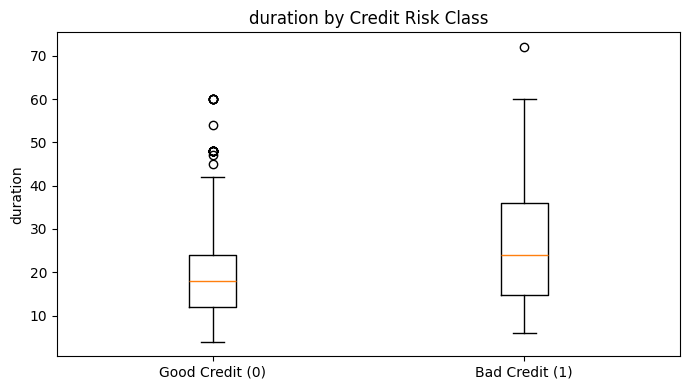

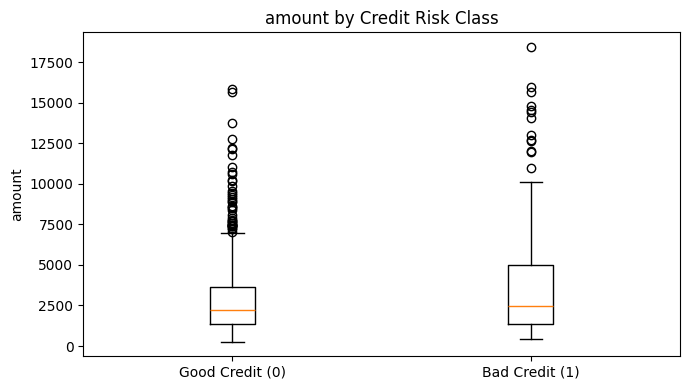

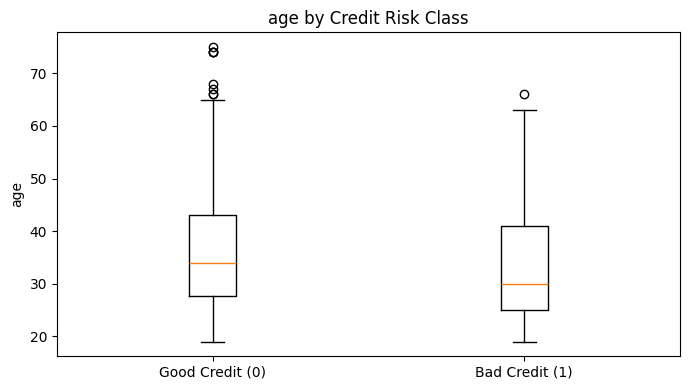

In [86]:
# Visualize numerical distributions separately for Good and Bad applicants.
for feature in numeric_features:

    good_values = development.loc[
        development["bad_credit"] == 0,
        feature
    ]

    bad_values = development.loc[
        development["bad_credit"] == 1,
        feature
    ]

    plt.figure(figsize=(7, 4))

    plt.boxplot(
        [good_values, bad_values],
        tick_labels=[
            "Good Credit (0)",
            "Bad Credit (1)"
        ]
    )

    plt.title(
        f"{feature} by Credit Risk Class"
    )

    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

#### **Interpretation**

The numerical predictors show visible differences between Good-credit and Bad-credit applicants.

- `duration`: Bad-credit applicants tend to have longer credit durations.
- `amount`: Bad-credit applicants tend to have larger credit amounts, although the right-skewed distribution means that large values can strongly affect the mean.
- `age`: Good-credit applicants tend to be somewhat older than Bad-credit applicants.

These patterns provide descriptive support for the predictive relevance of the numerical variables but are not used to revise the already-selected feature set.

### **14.5.2 Bad-Credit Rate by Category**

In [87]:
# Compare observed Bad-credit rates across categories for interpretation only.
categorical_bad_rates = {}

for feature in categorical_features:

    bad_rate = (
        development
        .groupby(feature)["bad_credit"]
        .agg(["count", "mean"])
        .rename(
            columns={
                "count": "Applicants",
                "mean": "Bad_Credit_Rate"
            }
        )
    )

    bad_rate["Bad_Credit_Rate"] = (
        bad_rate["Bad_Credit_Rate"] * 100
    )

    categorical_bad_rates[feature] = bad_rate

    print(f"\n{feature}")
    display(bad_rate)


status


,Applicants,Bad_Credit_Rate
status,,
1,159,45.283019
2,179,34.636872
3,41,4.878049
4,261,9.195402



credit_history


,Applicants,Bad_Credit_Rate
credit_history,,
0,27,48.148148
1,33,54.545455
2,315,27.301587
3,55,23.636364
4,210,14.285714



purpose


,Applicants,Bad_Credit_Rate
purpose,,
0,154,33.116883
1,65,12.307692
2,111,24.324324
3,180,18.888889
4,6,16.666667
5,17,23.529412
6,35,42.857143
8,7,0.000000
9,56,28.571429



savings


,Applicants,Bad_Credit_Rate
savings,,
1,372,30.645161
2,74,28.378378
3,43,18.604651
4,31,6.451613
5,120,12.500000



employment_duration


,Applicants,Bad_Credit_Rate
employment_duration,,
1,42,35.714286
2,117,35.042735
3,199,25.125628
4,121,14.876033
5,161,22.360248



installment_rate


,Applicants,Bad_Credit_Rate
installment_rate,,
1,96,22.916667
2,145,20.000000
3,98,24.489796
4,301,28.239203



personal_status_sex


,Applicants,Bad_Credit_Rate
personal_status_sex,,
1,29,34.482759
2,198,30.303030
3,354,21.186441
4,59,25.423729



other_debtors


,Applicants,Bad_Credit_Rate
other_debtors,,
1,578,25.086505
2,32,31.250000
3,30,16.666667



present_residence


,Applicants,Bad_Credit_Rate
present_residence,,
1,88,22.727273
2,196,27.551020
3,98,21.428571
4,258,25.193798



property


,Applicants,Bad_Credit_Rate
property,,
1,181,18.232044
2,144,25.000000
3,215,26.046512
4,100,35.000000



other_installment_plans


,Applicants,Bad_Credit_Rate
other_installment_plans,,
1,91,34.065934
2,28,35.714286
3,521,22.840691



housing


,Applicants,Bad_Credit_Rate
housing,,
1,101,35.643564
2,469,21.321962
3,70,34.285714



number_credits


,Applicants,Bad_Credit_Rate
number_credits,,
1,393,26.208651
2,220,23.181818
3,22,22.727273
4,5,20.000000



job


,Applicants,Bad_Credit_Rate
job,,
1,20,30.000000
2,130,19.230769
3,398,24.874372
4,92,32.608696



people_liable


,Applicants,Bad_Credit_Rate
people_liable,,
1,100,18.000000
2,540,26.296296



telephone


,Applicants,Bad_Credit_Rate
telephone,,
1,388,26.288660
2,252,23.015873



foreign_worker


,Applicants,Bad_Credit_Rate
foreign_worker,,
1,30,10.000000
2,610,25.737705


# **15. Historical Benchmark Evaluation**

After the final prediction rule has been frozen, a fresh model is fitted on all 640 Development observations.

The following components remain fixed:

- final feature-count strategy,
- final Development feature set,
- model family,
- hyperparameters,
- classification threshold.

The 160-row Historical Benchmark is then used only to evaluate this already-frozen prediction rule.

No modelling decision is revised after observing Benchmark performance.

## **15.1 Fit the Frozen Final Rule on Development Data**

In [88]:
# Reconstruct the already-selected final model configuration.
# No model or hyperparameter search is performed here.
selected_candidate = next(
    candidate
    for candidate in model_candidates
    if candidate["model_name"] == final_model_name
)

final_model_builder = selected_candidate["model_builder"]
# Use the final Development feature set determined in Section 14
final_preprocessor = build_feature_preprocessor(final_features)

final_model = final_model_builder(final_preprocessor, **final_params)

X_development_final = development[final_features]

y_development_final = development["bad_credit"]

final_model.fit(X_development_final, y_development_final)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## **15.2 Benchmark Prediction and Evaluation**

The fitted final model is applied to the 160-row historical benchmark.

The benchmark labels are used only to evaluate the already-frozen prediction rule.

No feature set, model parameter, or threshold is changed after observing these results.

In [89]:
# Apply exactly the same final Development feature set to the Benchmark.
X_benchmark = benchmark[final_features]

y_benchmark = benchmark["bad_credit"]
# Generate Benchmark probabilities without any refitting or tuning.
benchmark_prob = final_model.predict_proba(X_benchmark)[:, 1]
# Apply the frozen classification threshold selected from Development OOF predictions.
benchmark_pred = (benchmark_prob >= final_threshold).astype(int)

In [90]:
tn, fp, fn, tp = confusion_matrix(y_benchmark, benchmark_pred).ravel()

benchmark_cost = 5 * fn + fp

benchmark_average_cost = (benchmark_cost / len(y_benchmark))

benchmark_cost_per_100 = (benchmark_average_cost * 100)

In [91]:
benchmark_metrics = pd.DataFrame({
    "Metric": [
        "TN",
        "FP",
        "FN",
        "TP",
        "Total Cost",
        "Average Cost per Applicant",
        "Cost per 100 Applicants",
        "Accuracy",
        "Precision Bad",
        "Recall Bad",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],

    "Value": [
        tn,
        fp,
        fn,
        tp,
        benchmark_cost,
        benchmark_average_cost,
        benchmark_cost_per_100,

        accuracy_score(
            y_benchmark,
            benchmark_pred
        ),

        precision_score(
            y_benchmark,
            benchmark_pred,
            zero_division=0
        ),

        recall_score(
            y_benchmark,
            benchmark_pred
        ),

        roc_auc_score(
            y_benchmark,
            benchmark_prob
        ),

        average_precision_score(
            y_benchmark,
            benchmark_prob
        ),

        brier_score_loss(
            y_benchmark,
            benchmark_prob
        )
    ]
})

benchmark_metrics

,Metric,Value
0,TN,76.000000
1,FP,44.000000
2,FN,11.000000
3,TP,29.000000
4,Total Cost,99.000000
5,Average Cost per Applicant,0.618750
6,Cost per 100 Applicants,61.875000
7,Accuracy,0.656250
8,Precision Bad,0.397260
9,Recall Bad,0.725000


In [92]:
cost_comparison = pd.DataFrame({
    "Evaluation": [
        "Nested CV Outer",
        "Historical Benchmark"
    ],

    "N": [
        len(development),
        len(benchmark)
    ],

    "Total Cost": [
        feature_total_outer_cost,
        benchmark_cost
    ],

    "Average Cost per Applicant": [
        feature_total_outer_cost / len(development),
        benchmark_average_cost
    ],

    "Cost per 100 Applicants": [
        (
            feature_total_outer_cost
            / len(development)
            * 100
        ),
        benchmark_cost_per_100
    ]
})

cost_comparison

,Evaluation,N,Total Cost,Average Cost per Applicant,Cost per 100 Applicants
0,Nested CV Outer,640,372,0.58125,58.125
1,Historical Benchmark,160,99,0.61875,61.875


## **15.3 Benchmark Interpretation**

The frozen final prediction rule was evaluated on the 160-row Historical Benchmark without any further model, feature, or threshold tuning.

The benchmark achieved a total business cost of **99**.

Because the Development and Historical Benchmark datasets contain different numbers of observations, total cost should not be compared directly across the two datasets. Therefore, the business cost is also normalized by the number of applicants.

The resulting normalized costs are:

- **Nested CV Outer:** 372 / 640 = **0.5813 cost per applicant**
- **Historical Benchmark:** 99 / 160 = **0.6188 cost per applicant**

Equivalently:

- **Nested CV Outer:** **58.13 cost per 100 applicants**
- **Historical Benchmark:** **61.88 cost per 100 applicants**

The Historical Benchmark therefore produces a slightly higher normalized cost than the Nested-CV estimate, with a difference of approximately **3.75 cost units per 100 applicants**.

This relatively small difference indicates that the performance observed on the Historical Benchmark is reasonably consistent in terms of normalized business cost estimated by Nested Cross-Validation.

Importantly, the Historical Benchmark remains a diagnostic evaluation only. No feature-selection rule, model configuration, or classification threshold is modified after observing these results.

## **15.4 Extended Validation Diagnostics**

Additional diagnostic metrics are calculated for the Nested-CV Outer OOF predictions and the Historical Benchmark.

These analyses examine discrimination, calibration, business cost, and possible overfitting patterns.

They are diagnostic only and do not alter the frozen final prediction rule.

In [93]:
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.metrics import average_precision_score
from IPython.display import display

In [94]:
VALIDATION_DIR = PROJECT_ROOT / "outputs" / "validation_checks"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# Calculate diagnostic classification, discrimination, calibration and business metrics.
# These metrics are reported only after model selection has been completed.
def validation_metrics(actual, probability, threshold):
    actual = np.asarray(actual)
    probability = np.asarray(probability)
    prediction = (probability >= np.asarray(threshold)).astype(int)

    tn, fp, fn, tp = confusion_matrix(actual, prediction, labels=[0, 1]).ravel()
    auc = roc_auc_score(actual, probability)

    return {
        "N": len(actual),
        "Bad Rate": actual.mean(),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy_score(actual, prediction),
        "ROC-AUC": auc,
        "Average Precision": average_precision_score(actual, probability),
        "Recall Bad": tp / (tp + fn),
        "FPR Good": fp / (fp + tn),
        "Total Cost": 5 * fn + fp,
        "Average Cost": (5 * fn + fp) / len(actual),
        "Brier": brier_score_loss(actual, probability)
    }

print("Model:", final_model_name)
print("Parameters:", final_params)
print("Frozen threshold:", final_threshold)


Model: Logistic Regression
Parameters: {'C': 0.1, 'class_weight': 'balanced'}
Frozen threshold: 0.41


In [95]:
validation_oof = feature_outer_predictions.merge(
    feature_outer_results[["Outer Fold", "Threshold"]],
    on="Outer Fold", how="left", validate="many_to_one"
)

prior_by_fold = {}
for fold in feature_outer_results["Outer Fold"]:
    assignment, train_part, val_part = get_outer_data(
        development, nested_folds, fold
    )
    prior_by_fold[fold] = train_part["bad_credit"].mean()

validation_oof["Base Probability"] = (
    validation_oof["Outer Fold"].map(prior_by_fold)
)

validation_benchmark = pd.DataFrame({
    "Id": benchmark["Id"].to_numpy(),
    "Actual": np.asarray(y_benchmark),
    "P(Bad)": np.asarray(benchmark_prob),
    "Prediction": np.asarray(benchmark_pred),
    "Threshold": float(final_threshold),
    "Base Probability": development["bad_credit"].mean()
})

validation_sets = {
    "Nested OOF 640": validation_oof,
    "Benchmark 160": validation_benchmark
}

if not validation_oof["Id"].is_unique or set(validation_oof["Id"]) != set(development["Id"]):
    raise ValueError("OOF IDs do not match Development. Check the original CV output.")

for name, data in validation_sets.items():
    prediction = (data["P(Bad)"].to_numpy() >= data["Threshold"].to_numpy()).astype(int)
    if not np.array_equal(prediction, data["Prediction"].to_numpy()):
        raise ValueError(f"{name}: probabilities, thresholds and saved predictions do not match.")
    if data[["Actual", "P(Bad)", "Threshold", "Base Probability"]].isna().any().any():
        raise ValueError(f"{name}: missing evaluation values.")

for name, data in validation_sets.items():
    print(name, "- N:", len(data), "- Bad rate:", data["Actual"].mean())

Nested OOF 640 - N: 640 - Bad rate: 0.25
Benchmark 160 - N: 160 - Bad rate: 0.25


### **15.4.1 Overall Metrics and Simple Baselines**

The model is compared with two simple decision rules:

- **All Good:** classify every applicant as Good credit.
- **All Bad:** classify every applicant as Bad credit.

Because a False Negative costs five times as much as a False Positive, accuracy alone is not sufficient for model evaluation.

The primary business metric remains:

**Cost = 5 × FN + FP**

In [96]:
metric_rows = []
baseline_rows = []

for name, data in validation_sets.items():
    result = validation_metrics(data["Actual"], data["P(Bad)"], data["Threshold"])
    result["Dataset"] = name
    metric_rows.append(result)

    for rule, prediction in [
        ("Model", data["Prediction"].to_numpy()),
        ("All Good", np.zeros(len(data), dtype=int)),
        ("All Bad", np.ones(len(data), dtype=int))
    ]:
        tn, fp, fn, tp = confusion_matrix(
            data["Actual"], prediction, labels=[0, 1]
        ).ravel()
        baseline_rows.append({
            "Dataset": name, "Rule": rule,
            "Accuracy": accuracy_score(data["Actual"], prediction),
            "FN": fn, "FP": fp,
            "Total Cost": 5 * fn + fp,
            "Average Cost": (5 * fn + fp) / len(data)
        })

validation_summary = pd.DataFrame(metric_rows).set_index("Dataset")
baseline_comparison = pd.DataFrame(baseline_rows)

display(validation_summary.round(4).T)
display(baseline_comparison.round(4))

Dataset,Nested OOF 640,Benchmark 160
N,640.0000,160.0000
Bad Rate,0.2500,0.2500
TN,263.0000,76.0000
FP,217.0000,44.0000
FN,31.0000,11.0000
TP,129.0000,29.0000
Accuracy,0.6125,0.6562
ROC-AUC,0.7448,0.7292
Average Precision,0.5065,0.4640
Recall Bad,0.8062,0.7250


,Dataset,Rule,Accuracy,FN,FP,Total Cost,Average Cost
0,Nested OOF 640,Model,0.6125,31,217,372,0.5812
1,Nested OOF 640,All Good,0.7500,160,0,800,1.2500
2,Nested OOF 640,All Bad,0.2500,0,480,480,0.7500
3,Benchmark 160,Model,0.6562,11,44,99,0.6188
4,Benchmark 160,All Good,0.7500,40,0,200,1.2500
5,Benchmark 160,All Bad,0.2500,0,120,120,0.7500


### **15.4.2 Calibration and Brier Score**

Calibration compares predicted Bad-credit probabilities with observed Bad-credit rates.

The probability range is divided into five score bands.

A well-calibrated model should produce predicted probabilities that are reasonably close to the observed Bad-credit rate within each band.

The Brier Score measures squared probability error, with lower values indicating better probabilistic prediction.

This analysis is diagnostic only; no probability recalibration is fitted.

,Dataset,Model Brier,Training-prior Brier
0,Nested OOF 640,0.1647,0.1875
1,Benchmark 160,0.1973,0.1875


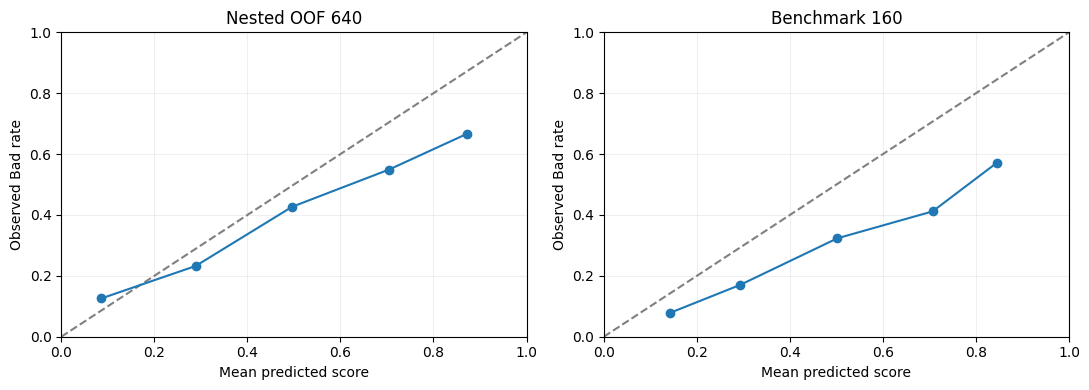

In [97]:
def calibration_table(actual, probability):
    table = pd.DataFrame({"Actual": np.asarray(actual), "Score": np.asarray(probability)})
    table["Band"] = pd.cut(
        table["Score"], bins=[0, .2, .4, .6, .8, 1], include_lowest=True
    )
    result = table.groupby("Band", observed=True).agg(
        N=("Actual", "size"),
        Bad_Count=("Actual", "sum"),
        Mean_Score=("Score", "mean"),
        Observed_Bad_Rate=("Actual", "mean")
    ).reset_index()
    result["Observed_minus_Predicted"] = result["Observed_Bad_Rate"] - result["Mean_Score"]
    return result


prior_by_fold = {}
for fold in feature_outer_results["Outer Fold"]:
    assignment, train_part, val_part = get_outer_data(
        development, nested_folds, fold
    )
    prior_by_fold[fold] = train_part["bad_credit"].mean()

for name, data in validation_sets.items():
    if "Outer Fold" in data.columns:
        data["Base Probability"] = data["Outer Fold"].map(prior_by_fold)
    else:
        # The other core evaluation table is Benchmark 160.
        data["Base Probability"] = development["bad_credit"].mean()

calibration_tables = []
brier_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, data) in zip(axes, validation_sets.items()):
    table = calibration_table(data["Actual"], data["P(Bad)"])
    table.insert(0, "Dataset", name)
    calibration_tables.append(table)

    brier_rows.append({
        "Dataset": name,
        "Model Brier": brier_score_loss(data["Actual"], data["P(Bad)"]),
        "Training-prior Brier": brier_score_loss(data["Actual"], data["Base Probability"])
    })
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.plot(table["Mean_Score"], table["Observed_Bad_Rate"], "o-")
    ax.set(title=name, xlabel="Mean predicted score", ylabel="Observed Bad rate",
           xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=.2)

calibration_results = pd.concat(calibration_tables, ignore_index=True)
brier_comparison = pd.DataFrame(brier_rows)
display(brier_comparison.round(4))
plt.tight_layout()
plt.savefig(VALIDATION_DIR / "calibration.png", dpi=150)
plt.show()

### **15.4.3 Train–Validation Diagnostics**

Training and Outer-Validation performance are compared within each Nested-CV fold to inspect possible overfitting.

The original Outer-fold winner is reconstructed using the feature set, model configuration, and threshold selected for that fold.

Differences between Training and Validation metrics are descriptive diagnostics.

They are not used to rerun model selection or alter the final prediction rule.

In [98]:
# Compare Training and Outer-Validation performance for each Nested-CV fold.
# This is a descriptive overfitting diagnostic only.

overfit_rows = []

for _, rule in feature_outer_results.iterrows():

    fold = int(rule["Outer Fold"])

    assignment, train_part, val_part = get_outer_data(
        development,
        nested_folds,
        fold
    )

    features = rule["Selected Features"]

    builder = next(
        candidate["model_builder"]
        for candidate in model_candidates
        if candidate["model_name"] == rule["Selected Model"]
    )

    diagnostic_model = builder(
        build_feature_preprocessor(features),
        **rule["Params"]
    )

    diagnostic_model.fit(
        train_part[features],
        train_part["bad_credit"]
    )

    for sample, part in [
        ("Training", train_part),
        ("Validation", val_part)
    ]:

        probability = diagnostic_model.predict_proba(
            part[features]
        )[:, 1]

        result = validation_metrics(
            part["bad_credit"],
            probability,
            rule["Threshold"]
        )

        result["Outer Fold"] = fold
        result["Sample"] = sample
        result["Model"] = rule["Selected Model"]
        result["Threshold"] = rule["Threshold"]

        overfit_rows.append(result)


overfit_checks = pd.DataFrame(overfit_rows)

display(
    overfit_checks[
        [
            "Outer Fold",
            "Sample",
            "Model",
            "Threshold",
            "ROC-AUC",
            "Average Cost"
        ]
    ].round(4)
)


fold_variation = (
    overfit_checks
    .groupby("Sample")[
        [
            "ROC-AUC",
            "Average Cost"
        ]
    ]
    .agg(["mean", "std"])
)

display(fold_variation.round(4))


overfit_gaps = overfit_checks.pivot(
    index="Outer Fold",
    columns="Sample",
    values=[
        "ROC-AUC",
        "Average Cost"
    ]
)

overfit_gaps["Train AUC minus Validation AUC"] = (
    overfit_gaps[("ROC-AUC", "Training")]
    - overfit_gaps[("ROC-AUC", "Validation")]
)

overfit_gaps["Validation Cost minus Train Cost"] = (
    overfit_gaps[("Average Cost", "Validation")]
    - overfit_gaps[("Average Cost", "Training")]
)

display(overfit_gaps.round(4))

print("Fold standard deviations are descriptive, not confidence intervals.")

,Outer Fold,Sample,Model,Threshold,ROC-AUC,Average Cost
0,1,Training,RBF SVM,0.19,0.9096,0.4082
1,1,Validation,RBF SVM,0.19,0.7178,0.6484
2,2,Training,Logistic Regression,0.29,0.8567,0.4238
3,2,Validation,Logistic Regression,0.29,0.8037,0.5156
4,3,Training,Logistic Regression,0.15,0.8623,0.3965
5,3,Validation,Logistic Regression,0.15,0.8353,0.3828
6,4,Training,Logistic Regression,0.07,0.8848,0.4258
7,4,Validation,Logistic Regression,0.07,0.7331,0.6562
8,5,Training,Gradient Boosting,0.21,0.9045,0.3477
9,5,Validation,Gradient Boosting,0.21,0.7124,0.7031


ROC-AUC         Average Cost        
              mean     std         mean     std
Sample                                         
Training    0.8836  0.0239       0.4004  0.0318
Validation  0.7604  0.0556       0.5812  0.1310

ROC-AUC            Average Cost            Train AUC minus Validation AUC Validation Cost minus Train Cost
Sample     Training Validation     Training Validation                                                                
Outer Fold                                                                                                            
1            0.9096     0.7178       0.4082     0.6484                         0.1918                           0.2402
2            0.8567     0.8037       0.4238     0.5156                         0.0530                           0.0918
3            0.8623     0.8353       0.3965     0.3828                         0.0271                          -0.0137
4            0.8848     0.7331       0.4258     0.6562                         0.1517                           0.2305
5            0.9045     0.7124       0.3477     0.7031                         0.1921                           0.3555

Fold standard deviations are descriptive, not confidence intervals.


#### **Diagnostic Summary**

The Nested-CV OOF predictions show better probabilistic performance than the simple training-prior baseline, while the Historical Benchmark shows weaker Brier performance, indicating some deterioration in probability calibration on the external sample.

Training performance is generally stronger than Outer-Validation performance, with the largest gaps occurring in several folds. This suggests some model-selection instability and overfitting risk.

These diagnostics do not alter the frozen prediction rule; the Outer-CV and Historical Benchmark results remain the relevant out-of-sample evaluations.

# **16. Final Refit on All Labeled Data**

After the final prediction rule has been evaluated on the Historical Benchmark, the 640 Development observations and 160 Historical Benchmark observations are combined to form the complete set of 800 labeled observations.

This stage is a **deployment refit**, not another model-selection stage.

The following modelling choices remain fixed from Development:

- feature-count strategy,
- feature-ranking method,
- model family,
- hyperparameters,
- preprocessing rules,
- classification threshold.

The association-based ranking procedure is then refitted on all 800 labeled observations to determine the exact predictors used by the deployment model.

Therefore, the exact predictor names may differ from those used during Historical Benchmark evaluation, while the selected Top-k strategy remains unchanged.

No new feature-count strategy, model configuration, or threshold is selected at this stage.

## **16.1 Refit the Selected Feature-Selection Procedure**

The selected feature-count strategy and association-ranking method are now refitted using all 800 labeled observations.

Only the exact predictor ranking and resulting Top-k predictor names are relearned.

The feature count, model family, hyperparameters, preprocessing rules, and classification threshold remain fixed.

In [99]:
# Combine all labeled observations only after Benchmark evaluation is complete.
# Benchmark labels are now used for deployment refitting, not for model selection.
full_labeled = pd.concat([development, benchmark], ignore_index=True)

print("Full labeled data:", full_labeled.shape)

Full labeled data: (800, 22)


In [100]:
# Confirm the target distribution in the complete 800-row labeled dataset.
full_labeled["bad_credit"].value_counts()

bad_credit
0    600
1    200
Name: count, dtype: int64

In [101]:
X_full_all = full_labeled[ALL_FEATURES]

y_full = full_labeled["bad_credit"]

full_final_features, full_association_table = (
    select_top_k_features(
        X_train=X_full_all,
        y_train=y_full,
        k=final_n_features))
# Refit the already-selected association-ranking procedure on all 800 rows.
# The Top-k count is fixed; only the exact predictor names are relearned.

In [102]:
print("Final deployment feature strategy:", final_feature_strategy)

print("Number of features:", len(full_final_features))

print("\nSelected features on all 800 labeled rows:")
for feature in full_final_features:
    print("-", feature)

Final deployment feature strategy: Top_14
Number of features: 14

Selected features on all 800 labeled rows:
- status
- credit_history
- purpose
- duration
- savings
- property
- employment_duration
- housing
- amount
- other_installment_plans
- age
- installment_rate
- foreign_worker
- personal_status_sex


In [103]:
full_association_table

,Feature,Method,Association Score
0,status,Cramer's V,0.346057
1,credit_history,Cramer's V,0.251961
2,purpose,Cramer's V,0.200936
3,duration,Point-Biserial,0.188310
4,savings,Cramer's V,0.169610
5,property,Cramer's V,0.149001
6,employment_duration,Cramer's V,0.145549
7,housing,Cramer's V,0.141678
8,amount,Point-Biserial,0.137515
9,other_installment_plans,Cramer's V,0.111615


In [104]:
# Show the deployment ranking and final retained predictors.
deployment_feature_ranking = full_association_table.copy()

deployment_feature_ranking.insert(
    0,
    "Rank",
    range(1, len(deployment_feature_ranking) + 1)
)

deployment_feature_ranking["Deployment Status"] = (
    deployment_feature_ranking["Feature"]
    .isin(full_final_features)
    .map({
        True: "Selected",
        False: "Dropped"
    })
)

deployment_feature_ranking

,Rank,Feature,Method,Association Score,Deployment Status
0,1,status,Cramer's V,0.346057,Selected
1,2,credit_history,Cramer's V,0.251961,Selected
2,3,purpose,Cramer's V,0.200936,Selected
3,4,duration,Point-Biserial,0.188310,Selected
4,5,savings,Cramer's V,0.169610,Selected
5,6,property,Cramer's V,0.149001,Selected
6,7,employment_duration,Cramer's V,0.145549,Selected
7,8,housing,Cramer's V,0.141678,Selected
8,9,amount,Point-Biserial,0.137515,Selected
9,10,other_installment_plans,Cramer's V,0.111615,Selected


In [105]:
# Compare the Development evaluation features with the 800-row deployment features.
feature_refit_comparison = pd.DataFrame({
    "Feature": ALL_FEATURES
})

feature_refit_comparison["Development Final"] = (
    feature_refit_comparison["Feature"]
    .isin(final_features)
    .map({True: "Selected", False: "Dropped"})
)

feature_refit_comparison["Deployment Final"] = (
    feature_refit_comparison["Feature"]
    .isin(full_final_features)
    .map({True: "Selected", False: "Dropped"})
)

feature_refit_comparison["Changed"] = (
    feature_refit_comparison["Development Final"]
    != feature_refit_comparison["Deployment Final"]
)

feature_refit_comparison

,Feature,Development Final,Deployment Final,Changed
0,status,Selected,Selected,False
1,duration,Selected,Selected,False
2,credit_history,Selected,Selected,False
3,purpose,Selected,Selected,False
4,amount,Selected,Selected,False
5,savings,Selected,Selected,False
6,employment_duration,Selected,Selected,False
7,installment_rate,Selected,Selected,False
8,personal_status_sex,Selected,Selected,False
9,other_debtors,Dropped,Dropped,False


## **16.2 Rebuild the Final Deployment Model**

A fresh modelling pipeline is constructed using the Top-k predictors selected from all 800 labeled observations.

The model family, hyperparameters, preprocessing rules, and classification threshold remain fixed at the values selected using Development data.

No new model search or threshold optimization is performed.

In [106]:
selected_candidate = next(
    candidate
    for candidate in model_candidates
    if candidate["model_name"] == final_model_name
)

final_model_builder = selected_candidate[
    "model_builder"
]
# Retrieve the already-selected model family.
# No candidate comparison is performed at this stage.

Build preprocessing:

In [107]:
# Rebuild preprocessing for the deployment feature set.
full_final_preprocessor = build_feature_preprocessor(full_final_features)

Build model:

In [108]:
# Rebuild the frozen model configuration for deployment.
full_final_model = final_model_builder(full_final_preprocessor, **final_params)

## **16.3 Fit the Final Deployment Pipeline on All 800 Labeled Rows**

The final deployment pipeline is fitted using all 800 labeled observations and the deployment feature set obtained in Section 16.1.

This fitted model is used only to generate predictions for the unlabeled Competition dataset.

No further validation, model selection, feature-count selection, or threshold optimization is performed.

In [109]:
# Final deployment fit using every available labeled observation.
X_full = full_labeled[full_final_features]
full_final_model.fit(X_full,y_full)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# **17. Competition Prediction**

The final deployment model fitted on all 800 labeled observations is applied to the 200 unlabeled Competition records.

The Competition data is restricted to the deployment predictors selected during the 800-row refit.

The model produces probabilities of **Bad credit**, consistent with the internal target definition:

- `bad_credit = 0`: Good credit
- `bad_credit = 1`: Bad credit

The frozen classification threshold is then applied to obtain internal Good/Bad predictions.

Finally, the internal predictions are converted back to the original `kredit` encoding required for submission.

Because Competition labels are unavailable, no evaluation metrics are calculated.

In [110]:
print("Competition shape:", competition.shape)
print("Final features:", full_final_features)
print("Final threshold:", final_threshold)
print("Final model:", final_model_name)

Competition shape: (200, 21)
Final features: ['status', 'credit_history', 'purpose', 'duration', 'savings', 'property', 'employment_duration', 'housing', 'amount', 'other_installment_plans', 'age', 'installment_rate', 'foreign_worker', 'personal_status_sex']
Final threshold: 0.41
Final model: Logistic Regression


## **17.1 Prepare Competition Predictors**

In [111]:
# Restrict Competition data to the exact predictors used by the deployment model.
X_competition = competition[full_final_features].copy()

print("Competition predictor shape:", X_competition.shape)

Competition predictor shape: (200, 14)


## **17.2 Generate Bad-Credit Probabilities**

In [112]:
# Probability of the positive internal class: bad_credit = 1 (Bad credit).
competition_prob = (
    full_final_model
    .predict_proba(X_competition)[:, 1]
)

print("Number of probabilities:", len(competition_prob))
print(competition_prob[:10])

Number of probabilities: 200
[0.50072971 0.38466677 0.50123241 0.45602097 0.8670785  0.23107281
 0.47781889 0.39185987 0.18273191 0.58684534]



## **17.3 Apply the Frozen Classification Threshold**

In [113]:
# Apply the frozen Development-selected threshold.
# 1 = predicted Bad credit, 0 = predicted Good credit.
competition_pred = (
    competition_prob
    >= final_threshold
).astype(int)

print("Threshold:", final_threshold)
print("Predicted Good:", (competition_pred == 0).sum())
print("Predicted Bad:", (competition_pred == 1).sum())

Threshold: 0.41
Predicted Good: 73
Predicted Bad: 127


## **17.4 Convert Internal Labels to `kredit` Format**

The model was trained using the internal target `bad_credit`, where:

- `0 = Good credit`
- `1 = Bad credit`

The original competition target `kredit` uses the opposite encoding:

- `1 = Good credit`
- `0 = Bad credit`

Therefore, the internal prediction is converted using:

**`kredit = 1 - bad_credit_prediction`**

In [114]:
# Convert internal bad_credit predictions back to the required kredit encoding.
competition_kredit = 1 - competition_pred

In [115]:
# Check the final submission class distribution.
pd.Series(
    competition_kredit,
    name="kredit"
).value_counts().sort_index()

kredit
0    127
1     73
Name: count, dtype: int64

## **17.5 Create the Submission Table**

In [116]:
# Build the submission using the original Competition IDs and kredit encoding.
submission = pd.DataFrame({
    "Id": competition["Id"].values,
    "kredit": competition_kredit
})

submission.head(10)

,Id,kredit
0,4,0
1,14,1
2,18,0
3,20,0
4,22,0
5,27,1
6,32,0
7,49,1
8,52,1
9,64,0


In [117]:
# Basic submission integrity checks.
assert len(submission) == len(competition)
assert submission["Id"].is_unique
assert set(submission["kredit"].unique()).issubset({0, 1})
assert submission["kredit"].notna().all()

print("Submission rows:", len(submission))
print("Unique IDs:", submission["Id"].nunique())
print("Missing predictions:", submission["kredit"].isna().sum())

Submission rows: 200
Unique IDs: 200
Missing predictions: 0


In [118]:
print(submission.shape)
print(submission.columns.tolist())
print(submission.isna().sum())

(200, 2)
['Id', 'kredit']
Id        0
kredit    0
dtype: int64


In [119]:
print(submission["kredit"].value_counts())
print(submission["kredit"].unique())

kredit
0    127
1     73
Name: count, dtype: int64
[0 1]


## **17.6 Save the Submission File**

In [120]:
# Save exactly two columns: Id and kredit.
submission_path = PROJECT_ROOT / "submission1.csv"

submission.to_csv(submission_path, index=False)

print("Saved to:",submission_path.relative_to(PROJECT_ROOT))

Saved to: submission1.csv


In [121]:
saved_submission = pd.read_csv(submission_path)

saved_submission.head()

,Id,kredit
0,4,0
1,14,1
2,18,0
3,20,0
4,22,0


In [122]:
print(saved_submission.shape)
print(saved_submission.columns.tolist())
print(saved_submission.isna().sum())

(200, 2)
['Id', 'kredit']
Id        0
kredit    0
dtype: int64


# **18. Export Model for Deployment**

The frozen final model and its metadata are exported for use by the Streamlit application.

The deployed application uses exactly the same fitted pipeline, selected features, and classification threshold as the final project model.

## **18.1 Prepare Artifact Paths**

In [123]:
import joblib

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = ARTIFACT_DIR / "final_model.joblib"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.joblib"

## **18.2 Build Deployment Metadata**

In [124]:
model_metadata = {
    "model_name": final_model_name,
    "params": final_params,

    # Deployment features selected after refitting Top_14 on all 800 rows
    "features": full_final_features,

    "feature_strategy": final_feature_strategy,
    "n_features": final_n_features,

    "threshold": float(final_threshold),

    "numeric_features": [
        f for f in numeric_features
        if f in full_final_features
    ],

    "categorical_features": [
        f for f in categorical_features
        if f in full_final_features
    ],

    "category_values": {
        feature: sorted(
            full_labeled[feature]
            .dropna()
            .unique()
            .tolist()
        )
        for feature in full_final_features
        if feature in categorical_features
    },

    "numeric_defaults": {
        feature: float(
            full_labeled[feature].median()
        )
        for feature in full_final_features
        if feature in numeric_features
    }
}

In [125]:
print("Model:", model_metadata["model_name"])
print("Params:", model_metadata["params"])
print("Feature strategy:", model_metadata["feature_strategy"])
print("Number of features:", model_metadata["n_features"])
print("Features:", model_metadata["features"])
print("Threshold:", model_metadata["threshold"])

Model: Logistic Regression
Params: {'C': 0.1, 'class_weight': 'balanced'}
Feature strategy: Top_14
Number of features: 14
Features: ['status', 'credit_history', 'purpose', 'duration', 'savings', 'property', 'employment_duration', 'housing', 'amount', 'other_installment_plans', 'age', 'installment_rate', 'foreign_worker', 'personal_status_sex']
Threshold: 0.41


## **18.3 Save Deployment Artifacts**

In [126]:
joblib.dump(full_final_model, MODEL_PATH)

joblib.dump(model_metadata, METADATA_PATH)

print("Saved model:", MODEL_PATH.relative_to(PROJECT_ROOT))
print("Saved metadata:", METADATA_PATH.relative_to(PROJECT_ROOT))

Saved model: artifacts\final_model.joblib
Saved metadata: artifacts\model_metadata.joblib


In [127]:
print("Model:", model_metadata["model_name"])
print("Features match:", model_metadata["features"] == full_final_features)
print("Threshold:", model_metadata["threshold"])
print("Number of deployment features:", len(model_metadata["features"]))

Model: Logistic Regression
Features match: True
Threshold: 0.41
Number of deployment features: 14
